<a href="https://colab.research.google.com/github/thisaraniNJ/Individual_Research_Project/blob/dev/UniFoil_Preprocessing_Visualisation_Standalone_corrected.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 1. Install/check the required Python packages

The embedded preprocessing code uses NumPy, Pandas and Parquet output. Matplotlib is used here for visualisations; `pyarrow` enables Parquet reading/writing.

In [1]:
import importlib.util
import subprocess
import sys

required = {
    "numpy": "numpy",
    "pandas": "pandas",
    "matplotlib": "matplotlib",
    "pyarrow": "pyarrow",
}
missing = [package for module, package in required.items() if importlib.util.find_spec(module) is None]
if missing:
    print("Installing missing packages:", ", ".join(missing))
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
else:
    print("All notebook packages are already available.")

All notebook packages are already available.


## 2. Connect Google Drive (Google Colab only)

If you are using local Jupyter instead of Colab, this cell simply skips the Drive mount. You can change the paths in the next cell.

In [2]:
from pathlib import Path

try:
    from google.colab import drive
    if not Path("/content/drive/MyDrive").exists():
        drive.mount("/content/drive")
    else:
        print("Google Drive already appears to be mounted.")
except ImportError:
    print("Not running in Google Colab. Use local paths in the configuration cell if needed.")

Mounted at /content/drive


## 3. Configure paths and processing size

The defaults match the expected UniFoil project folder layout. If your raw data is stored elsewhere, change `PROJECT` before continuing. `SEED` is the fixed random seed used for every random sample (methodology Table 3.7).

In [3]:
from pathlib import Path
import os

PROJECT = Path("/content/drive/MyDrive/unifoil_project")
RAW_DIR = PROJECT / "raw_data"
PREP_BASE_DIR = PROJECT / "prepared"

# First run: process a manageable trial. Change to None only when ready for the full dataset.
MAX_CASES = None          # None = all cases (as in the chapter); a number such as 300 = a quick trial only
RUN_PREPROCESS = True    # False means use an already prepared output folder
SAVE_PLOTS = True        # save generated figures under PREP_DIR/visualizations
SEED = 2026              # fixed seed for every random sample (methodology Table 3.7)

PREP_DIR = PREP_BASE_DIR / (f"try_{MAX_CASES}" if MAX_CASES is not None else "")
print("Raw data folder:", RAW_DIR)
print("Output folder:", PREP_DIR)
print("Case limit:", MAX_CASES if MAX_CASES is not None else "all cases")

Raw data folder: /content/drive/MyDrive/unifoil_project/raw_data
Output folder: /content/drive/MyDrive/unifoil_project/prepared
Case limit: all cases


## 4. Define the preprocessing code inside this notebook

The functions below are embedded directly in this notebook. They read the UniFoil raw-data folder, prepare case and surface tables, apply the screening flags, and save the outputs. **You do not need to upload or keep a separate `02_preprocess.py` file.**

Run these code cells from top to bottom once after setting the paths above. The raw-data files themselves must already be downloaded in the folder described in Section 5.


In [4]:
# Imports and fixed preprocessing settings
import csv
import glob
import gzip
import io
import os
import pickle
import re
import zipfile
from collections import defaultdict
from collections.abc import Mapping

import numpy as np
import pandas as pd

# Batch size controls checkpoint frequency, not the number of cases in the dataset.
BATCH = 2000

# Convergence rule (methodology Tables 3.4 and 3.6): the total residual must fall by at least 6 orders of
# magnitude. Own choice, fixed in advance, because UniFoil does not publish its stopping rule.
RESIDUAL_DROP_MIN = 6.0
DROP_TOLERANCE = 0.0      # no rounding margin: 'fewer than 6 orders' means below 6.0 exactly
SENSITIVITY_DROP = 5.0    # the looser rule compared as a sensitivity check (Table 3.4)
CD_HISTORY_TAIL_MAX = 0.001  # Sensitivity subset only; it does not affect the main RQ1 decision.
MIN_SURFACE_POINTS = 50
MIN_N_STATIONS = 5  # Reported N-factor station count only; not a case-removal rule.
X_TOL = 0.01        # margin of the check 'every x/c lies between 0 and 1': 0.01c, the agreement tolerance of Table 3.6
PINNED_REVISION = "6724bb9"  # dataset revision of the whole study (methodology Table 3.6)

# Files needed for each research question.
RQ1_FILES = ("analysis", "convergence", "slices")
RQ2_FILES = ("transiLoc.dat",)
CHECK_FILES = ("nfactor_ts.dat", "bledge_info.dat")  # Cross-check only; missing files do not remove RQ1 cases.

WHOLE = "transi/airfoil_data_from_simulations.zip"
SURFACES = ("upper", "lower")
CASE_RE = re.compile(r"airfoil_(\d+)_G\d+_[A-Za-z0-9]+_L\d+_case_(\d+)")
ANALYSIS_RE = re.compile(r"(\d+)_case_(\d+)_analysis\.csv$")
CONV_RE = re.compile(r"(\d+)_case_(\d+)_convergence\.pkl$")

print("Preprocessing functions are defined in this notebook; no external 02_preprocess.py is required.")
print(f"Convergence rule: residual drop of at least {RESIDUAL_DROP_MIN:g} orders (own choice, fixed in advance); "
      f"{SENSITIVITY_DROP:g} orders compared as a check.")

Preprocessing functions are defined in this notebook; no external 02_preprocess.py is required.
Convergence rule: residual drop of at least 6 orders (own choice, fixed in advance); 5 orders compared as a check.


### 4.1 Read flight-condition and solver-result files

In [5]:
def to_float(text):
    return float(text.replace("D", "E").replace("d", "e"))      # Fortran writes 1.0D-03


def numbers(line):
    try:
        return [to_float(p) for p in line.replace(",", " ").split()]
    except ValueError:
        return None


def surface_of(line):
    low = line.lower()
    return "upper" if "upper" in low else ("lower" if "lower" in low else None)


def read_analysis(text):
    """analysis.csv: 'name,value' lines, then a line of names (CL,CD) with their values below"""
    rows = [[c.strip() for c in line.split(",")] for line in text.splitlines() if line.strip()]
    out, i = {}, 0
    while i < len(rows):
        r = rows[i]
        if len(r) == 2 and numbers(r[1]) and not numbers(r[0]):
            out[r[0].lower()] = numbers(r[1])[0]
        elif not any(numbers(c) for c in r) and i + 1 < len(rows) and numbers(",".join(rows[i + 1])):
            vals = numbers(",".join(rows[i + 1]))
            out.update({k.lower(): v for k, v in zip(r, vals)})
            i += 1
        i += 1
    return {"Mach": out.get("mach"), "AoA_stated": out.get("aoa"), "Re": out.get("reynolds"),
            "CL_reported": out.get("cl"), "CD_reported": out.get("cd")}

### 4.2 Read convergence history, transition locations, N-factor data and separation locations

Step 5 of the chapter: the envelope is formed from the N-factor of every frequency, and the envelope written by the solver itself (its 'enveloped curve' zones) is also kept for comparison.

In [6]:
# ---- convergence.pkl (saved by the solver) ----
# The tolerant unpickler below falls back to a stand-in class when optional solver classes are unavailable.
class _StandIn:
    """takes the place of any class that cannot be imported, keeping its data"""

    def __new__(cls, *a, **k):
        return object.__new__(cls)

    def __init__(self, *a, **k):
        pass

    def __setstate__(self, state):
        if isinstance(state, tuple) and len(state) == 2:
            state = {**(state[0] or {}), **(state[1] or {})}
        if isinstance(state, dict):
            self.__dict__.update(state)

    def __setitem__(self, k, v):
        self.__dict__.setdefault("_items", {})[k] = v


class TolerantUnpickler(pickle.Unpickler):
    def find_class(self, module, name):
        try:
            return super().find_class(module, name)
        except (ImportError, AttributeError):
            return type(name, (_StandIn,), {})


def read_convergence(raw):
    """iterations, residual drop (orders of magnitude), CD steadiness, and the last values of the
    solver's own coefficients. UniFoil's files hold a baseclasses CaseInsensitiveDict with the
    history of ADflow's monitor variables: totalR, CoefLift, CoefDrag, CoefPressureDrag,
    CoefViscousDrag, CoefMomentZ, ..."""
    obj = TolerantUnpickler(io.BytesIO(raw)).load()
    if isinstance(obj, Mapping):
        hist = obj["data"] if "data" in obj and isinstance(obj["data"], Mapping) else obj
    else:                                            # stand-in for the dict class: its data sits in .data
        d = getattr(obj, "__dict__", {})
        hist = d.get("data", d) if isinstance(d.get("data"), Mapping) else d
    arrays = {}
    for k, v in (hist or {}).items():
        try:
            a = np.asarray(v, dtype=float).ravel()
        except (TypeError, ValueError):
            continue
        if a.size >= 2:
            arrays[re.sub(r"[^a-z0-9]", "", str(k).lower())] = a
    out = {"n_iter": max((a.size for a in arrays.values()), default=np.nan)}
    res = next((arrays[k] for k in ("totalr", "totalres", "rsdmassrms", "resrho", "residual") if k in arrays), None)
    if res is not None:
        r = np.abs(res[np.isfinite(res) & (res != 0)])
        out["residual_drop_orders"] = float(np.log10(r[0] / r[-1])) if len(r) >= 2 else np.nan
    for name, key in (("cl_solver", "coeflift"), ("cdp_solver", "coefpressuredrag"),
                      ("cdv_solver", "coefviscousdrag")):
        if key in arrays and np.isfinite(arrays[key][-1]):
            out[name] = float(arrays[key][-1])       # the solver's own values at the last iteration
    cd = arrays.get("coefdrag", arrays.get("cd"))
    if cd is not None:
        cd = cd[np.isfinite(cd)]
        tail = cd[-max(2, len(cd) // 10):]
        out["cd_last"] = float(cd[-1])
        out["cd_tail_rel_change"] = float((tail.max() - tail.min()) / max(abs(tail.mean()), 1e-12))
    return out


# ---- transition files ----
def read_transiloc(text):
    rows = [numbers(line) for line in text.splitlines() if line.strip()]
    rows = [r for r in rows if r]
    return {SURFACES[i]: rows[i][0] for i in range(min(2, len(rows)))}


def read_nfactor_envelope(text):
    """{surface: (x, N_envelope)}, the surfaces with an unreadable '****' zone, and the solver's own envelope.
    Each zone is one surface and one wave frequency (x/c = column 1, N = column 5). The envelope is
    the largest N over all frequencies at every station (N_TS of Shi et al. 2020). Not used for it:
    '****' zones (nonsense N up to 1e11) and all-zero rows. The solver's own 'enveloped curve' zones
    are read separately and returned as solver_env, kept for comparison (methodology step 5)."""
    curves, bad, cur = defaultdict(list), set(), None
    solver_curves = defaultdict(list)
    for line in text.splitlines():
        s = line.strip()
        if s.lower().startswith("zone"):
            cur = None
            side = surface_of(s)
            if side is None:
                continue
            if "envelop" in s.lower():                 # the solver's own envelope: kept for comparison
                if "*" not in s:
                    cur = ([], [])
                    solver_curves[side].append(cur)
                continue
            if "*" in s:
                bad.add(side)
                continue
            cur = ([], [])
            curves[side].append(cur)
            continue
        v = numbers(s)
        if cur is not None and v and len(v) >= 5 and any(v):
            cur[0].append(v[0])
            cur[1].append(v[4])
    env = {}
    for side, cs in curves.items():
        cs = [(np.array(x)[np.argsort(x)], np.array(n)[np.argsort(x)]) for x, n in cs if len(x) >= 2]
        if not cs:
            continue
        grid = np.unique(np.concatenate([x for x, _ in cs]))
        stack = [np.where((grid >= x[0]) & (grid <= x[-1]), np.interp(grid, x, n), -np.inf) for x, n in cs]
        env[side] = (grid, np.max(stack, axis=0))
    solver_env = {}
    for side, cs in solver_curves.items():
        x = np.concatenate([np.asarray(c[0], dtype=float) for c in cs])
        n = np.concatenate([np.asarray(c[1], dtype=float) for c in cs])
        if len(x) >= 2:
            order = np.argsort(x, kind="stable")
            solver_env[side] = (x[order], n[order])
    return env, bad, solver_env


def envelope_difference(ours, solver):
    """largest |our envelope - solver's envelope| at the solver's stations inside our envelope's range"""
    if ours is None or solver is None:
        return np.nan
    gx, gn = ours
    sx, sn = solver
    inside = (sx >= gx[0]) & (sx <= gx[-1])
    if not inside.any():
        return np.nan
    return float(np.max(np.abs(np.interp(sx[inside], gx, gn) - sn[inside])))


NF_COLS = ("nf_unnamed_zones",) + tuple(f"nf_{w}_{s}" for w in ("zones", "freq_zones", "freq_zones_usable", "stations")
                                         for s in SURFACES)
# the solver's own envelope: number of stations, and the largest difference from our envelope
SOLVER_ENV_COLS = tuple(f"{w}_{s}" for w in ("nf_solver_env_stations", "env_vs_solver_max_diff") for s in SURFACES)


def nfactor_columns(text):
    """the N-factor envelope, the '****' surfaces, what the file holds (written to cases.csv), and the
    solver's own envelope:
    nf_zones_<surface>              all zones named for that surface (0 = UniFoil wrote no stability results)
    nf_freq_zones_<surface>         of these, wave-frequency zones (not the 'enveloped curve', not '****')
    nf_freq_zones_usable_<surface>  of these, zones with at least 2 usable rows (5 numbers, not all zero),
                                    the only zones the envelope can be built from
    nf_stations_<surface>           stations in the envelope the reader built (0 = no usable N data)
    nf_unnamed_zones                zones named for no surface (should be 0)
    nf_solver_env_stations_<surface> stations in the solver's own envelope (0 = none in the file)
    env_vs_solver_max_diff_<surface> largest difference in N between our envelope and the solver's
    A surface with usable frequency zones but no envelope would mean the reader is losing data."""
    env, bad, solver_env = read_nfactor_envelope(text)
    cols = {"nf_unnamed_zones": 0, **{f"nf_{w}_{s}": 0 for w in ("zones", "freq_zones", "freq_zones_usable")
                                      for s in SURFACES}}
    zone = None                                    # [side, is_frequency_zone, usable rows]

    def close(z):
        if z and z[0] and z[1] and z[2] >= 2:
            cols[f"nf_freq_zones_usable_{z[0]}"] += 1
    for line in text.splitlines():
        s = line.strip()
        if s.lower().startswith("zone"):
            close(zone)
            side = surface_of(s)
            freq = side is not None and "envelop" not in s.lower() and "*" not in s
            zone = [side, freq, 0]
            if side is None:
                cols["nf_unnamed_zones"] += 1
            else:
                cols[f"nf_zones_{side}"] += 1
                cols[f"nf_freq_zones_{side}"] += freq
            continue
        v = numbers(s)
        if zone is not None and v and len(v) >= 5 and any(v):
            zone[2] += 1
    close(zone)
    for s in SURFACES:
        cols[f"nf_stations_{s}"] = len(env[s][0]) if s in env else 0
        cols[f"nf_solver_env_stations_{s}"] = len(solver_env[s][0]) if s in solver_env else 0
        cols[f"env_vs_solver_max_diff_{s}"] = envelope_difference(env.get(s), solver_env.get(s))
    return env, bad, cols, solver_env


def read_separation(text):
    """laminar-separation x/c per surface = last station of its zone in bledge_info.dat"""
    x_sep, side = {}, None
    for line in text.splitlines():
        s = line.strip()
        if s.lower().startswith("zone"):
            side = surface_of(s)
            continue
        v = numbers(s)
        if side and v:
            x_sep[side] = max(x_sep.get(side, -np.inf), v[0])
    return x_sep

### 4.3 Read the surface mesh and calculate geometry descriptors

In [7]:
# ---- slice file ----
def read_slice(text):
    """ADflow Tecplot slice -> dict of columns (XoC, YoC, CoefPressure, ...) and the line segments"""
    lines = text.splitlines()
    names, i = [], 0
    while i < len(lines):
        s = lines[i].strip()
        if s.lower().startswith("variables"):
            buf = s
            while i + 1 < len(lines) and lines[i + 1].strip().startswith('"'):
                i += 1
                buf += " " + lines[i]
            names = re.findall(r'"([^"]*)"', buf)
        elif s.lower().startswith("zone"):
            head = s
            while not (re.search(r"Nodes\s*=\s*\d+", head, re.I) and re.search(r"Elements\s*=\s*\d+", head, re.I)):
                i += 1
                head += " " + lines[i]
            n_nodes = int(re.search(r"Nodes\s*=\s*(\d+)", head, re.I).group(1))
            n_elem = int(re.search(r"Elements\s*=\s*(\d+)", head, re.I).group(1))
            i += 1
            while not numbers(lines[i]):
                i += 1
            data = np.array([numbers(l) for l in lines[i:i + n_nodes]], dtype=float)
            conn = np.array([numbers(l)[:2] for l in lines[i + n_nodes:i + n_nodes + n_elem]], dtype=int)
            return {n.lower(): data[:, k] for k, n in enumerate(names)}, conn
        i += 1
    raise ValueError("no zone in the slice file")


def split_surfaces(x, y, conn, tol=1e-7):
    """put the slice points in order round the airfoil and split them at the leading edge (smallest x)
    and trailing edge (largest x). ADflow writes a slice in a few pieces whose end points repeat, so
    points at the same place are merged first. Returns {surface: point indices, LE -> TE} or None."""
    key = np.round(np.c_[x, y] / tol).astype(np.int64)
    _, first, inv = np.unique(key, axis=0, return_index=True, return_inverse=True)
    inv = np.asarray(inv).ravel()
    nb = defaultdict(set)
    for a, b in conn - 1:
        if 0 <= a < len(x) and 0 <= b < len(x) and inv[a] != inv[b]:
            nb[inv[a]].add(inv[b])
            nb[inv[b]].add(inv[a])
    if len(nb) < 10 or any(len(v) != 2 for v in nb.values()):
        return None
    start = next(iter(nb))
    loop, prev, cur = [start], None, start
    while True:
        a, b = tuple(nb[cur])
        nxt = a if a != prev else b
        if nxt == start:
            break
        loop.append(nxt)
        prev, cur = cur, nxt
        if len(loop) > len(nb):
            return None
    idx = first[loop]
    le, te = int(np.argmin(x[idx])), int(np.argmax(x[idx]))
    n = len(idx)
    p1 = np.array([idx[(le + k) % n] for k in range((te - le) % n + 1)])
    p2 = np.array([idx[(le - k) % n] for k in range((le - te) % n + 1)])
    return {"upper": p1, "lower": p2} if y[p1].mean() >= y[p2].mean() else {"upper": p2, "lower": p1}


def shape_descriptors(xu, yu, xl, yl):
    """maximum thickness and camber (fractions of the chord) and where they are"""
    g = np.linspace(0, 1, 401)
    ou, ol = np.argsort(xu), np.argsort(xl)
    up, lo = np.interp(g, xu[ou], yu[ou]), np.interp(g, xl[ol], yl[ol])
    t, c = up - lo, 0.5 * (up + lo)
    return dict(t_max=float(t.max()), x_t_max=float(g[t.argmax()]),
                camber_max=float(c[np.abs(c).argmax()]), x_camber_max=float(g[np.abs(c).argmax()]))


# =============================================================================
# running
# =============================================================================

### 4.4 Find source files, process individual cases, screen data and write the report

In [8]:
class Store:
    """reads single files from the shard zips (via the manifest) and from the whole archive"""

    def __init__(self, raw):
        self.raw, self.zips = raw, {}

    def _zip(self, path):
        if path not in self.zips:
            self.zips[path] = zipfile.ZipFile(path)
        return self.zips[path]

    def shard(self, archive, shard, name):
        return self._zip(os.path.join(self.raw, "raw", os.path.basename(archive)[:-4], shard)).read(name)

    def whole(self, name):
        return self._zip(os.path.join(self.raw, "archives", WHOLE)).read(name)


def find_files(raw):
    """{(airfoil, case): {kind: location}} from the manifest and the whole archive"""
    files = defaultdict(dict)
    with gzip.open(os.path.join(raw, "manifest_files.csv.gz"), "rt", newline="") as fh:
        for r in csv.DictReader(fh):
            m = CASE_RE.search(r["name"])
            if not m:
                continue
            c, base = (int(m.group(1)), int(m.group(2))), os.path.basename(r["name"])
            if r["archive"].endswith("output_transi.zip") and base in ("transiLoc.dat", "nfactor_ts.dat", "bledge_info.dat"):
                files[c][base] = (r["archive"], r["shard"], r["name"])
            elif "output_aero_cutout" in r["archive"] and base.endswith("_slices.dat"):
                files[c]["slices"] = (r["archive"], r["shard"], r["name"])
    with zipfile.ZipFile(os.path.join(raw, "archives", WHOLE)) as z:
        for n in z.namelist():
            for kind, rx in (("analysis", ANALYSIS_RE), ("convergence", CONV_RE)):
                m = rx.search(n)
                if m:
                    files[(int(m.group(1)), int(m.group(2)))][kind] = n
    return files


def process_case(c, where, store):
    """everything for one case: (case row, surface rows, transition rows, solver-envelope rows)"""
    af, k = c
    row = dict(airfoil=af, case=k)
    surf, trans, solver_env_rows = [], [], []
    need = RQ1_FILES + RQ2_FILES + CHECK_FILES
    row["missing_files"] = ",".join(n for n in need if n not in where)
    if "analysis" in where:
        row.update(read_analysis(store.whole(where["analysis"]).decode("utf-8", "replace")))
    if "convergence" in where:
        try:
            row.update(read_convergence(store.whole(where["convergence"])))
        except Exception:
            row["convergence_unreadable"] = True
    if "slices" in where:
        try:
            cols, conn = read_slice(store.shard(*where["slices"]).decode("utf-8", "replace"))
            x, y = cols["xoc"], cols["yoc"]
            sides = split_surfaces(x, y, conn)
        except Exception:
            sides = None
        row["slice_ok"] = sides is not None
        if sides:
            for side in SURFACES:
                p = sides[side]
                row[f"n_points_{side}"] = len(p)
                surf.append(pd.DataFrame(dict(
                    airfoil=af, case=k, surface=side, i=np.arange(len(p), dtype=np.int16),
                    x=cols["xoc"][p], y=cols["yoc"][p], cp=cols["coefpressure"][p],
                    cf=cols["skinfrictionmagnitude"][p], cfx=cols["skinfrictionx"][p])))
            row.update(shape_descriptors(x[sides["upper"]], y[sides["upper"]], x[sides["lower"]], y[sides["lower"]]))
            row["cp_max"] = float(np.nanmax(cols["coefpressure"]))
    if "transiLoc.dat" in where:
        solver = read_transiloc(store.shard(*where["transiLoc.dat"]).decode("utf-8", "replace"))
        env, bad, solver_env = {}, set(), {}
        if "nfactor_ts.dat" in where:
            env, bad, nf, solver_env = nfactor_columns(store.shard(*where["nfactor_ts.dat"]).decode("utf-8", "replace"))
            row.update(nf)
        x_sep = read_separation(store.shard(*where["bledge_info.dat"]).decode("utf-8", "replace")) \
            if "bledge_info.dat" in where else {}
        for side in SURFACES:
            row[f"x_tr_solver_{side}"] = solver.get(side, np.nan)
            row[f"x_sep_{side}"] = x_sep.get(side, np.nan)
            row[f"bad_frequency_{side}"] = side in bad
            if side in env:
                gx, gn = env[side]
                trans.append(pd.DataFrame(dict(airfoil=af, case=k, surface=side, x=gx, N=gn)))
            if side in solver_env:                         # the solver's own envelope, kept for comparison
                sx, sn = solver_env[side]
                solver_env_rows.append(pd.DataFrame(dict(airfoil=af, case=k, surface=side, x=sx, N=sn)))
    return row, surf, trans, solver_env_rows


def column(df, name, default):
    return df[name] if name in df else pd.Series(default, index=df.index)


def as_bool(series):
    return series.map(lambda v: str(v).strip().lower() in ("true", "1", "1.0"))


def screen(df):
    """flags and the two keep decisions (thresholds in SETTINGS)"""
    f = pd.DataFrame(index=df.index)
    missing = column(df, "missing_files", "").fillna("").astype(str).str.split(",")

    def lacks(names):
        return missing.map(lambda m: any(n in m for n in names))
    # ---- RQ1: drag and crossover ----
    f["rq1_file_missing"] = lacks(RQ1_FILES)
    f["not_converged"] = ~(column(df, "residual_drop_orders", np.nan) >= RESIDUAL_DROP_MIN - DROP_TOLERANCE)
    cd = column(df, "CD_reported", np.nan)
    f["bad_surface_data"] = ~as_bool(column(df, "slice_ok", False)) | \
        ~((column(df, "n_points_upper", 0).fillna(0) >= MIN_SURFACE_POINTS) &
          (column(df, "n_points_lower", 0).fillna(0) >= MIN_SURFACE_POINTS))
    f["cd_not_positive"] = cd <= 0                     # Table 3.4: stored CD <= 0 (a missing CD means a missing file)
    # ---- RQ2: also a valid transition location on both surfaces ----
    f["transition_file_missing"] = lacks(RQ2_FILES)
    for side in SURFACES:
        x = column(df, f"x_tr_solver_{side}", np.nan)
        f[f"transition_missing_{side}"] = x.isna()                          # no value at all
        f[f"transition_placeholder_{side}"] = x.notna() & ~x.between(0, 1)  # a value, but not on the chord (e.g. 7.0)
        f[f"bad_frequency_{side}"] = as_bool(column(df, f"bad_frequency_{side}", False))
    # ---- reported only, never used to remove a case ----
    f["en_check_file_missing"] = lacks(CHECK_FILES)        # step 03 cannot cross-check with the e^N rule
    f["cd_history_unsteady"] = ~(column(df, "cd_tail_rel_change", np.nan) <= CD_HISTORY_TAIL_MAX)

    rq1 = ["rq1_file_missing", "not_converged", "bad_surface_data", "cd_not_positive"]
    rq2 = rq1 + ["transition_file_missing"] + [c for c in f.columns if c.startswith(
        ("transition_missing", "transition_placeholder", "bad_frequency"))]
    out = df.copy()
    for c in f.columns:
        out[f"flag_{c}"] = f[c].values
    out["keep_rq1"] = ~f[rq1].any(axis=1)
    out["keep_rq2"] = ~f[rq2].any(axis=1)
    out["keep_rq1_strict"] = out.keep_rq1 & ~f.cd_history_unsteady      # sensitivity subset for RQ1
    out["removed_from_rq1_because"] = f.apply(lambda r: ",".join(c for c in rq1 if r[c]), axis=1)
    out["removed_from_rq2_because"] = f.apply(lambda r: ",".join(c for c in rq2 if r[c]), axis=1)
    return out


def report(cases, out_dir, raw_dir=None):
    lines = ["PREPROCESSING REPORT", "", f"cases: {len(cases):,} on {cases.airfoil.nunique():,} airfoils",
             f"kept for RQ1 (drag, crossover):      {int(cases.keep_rq1.sum()):,} ({cases.keep_rq1.mean():.1%})",
             f"kept for RQ2 (also transition valid): {int(cases.keep_rq2.sum()):,} ({cases.keep_rq2.mean():.1%})",
             f"RQ1 sensitivity subset (also steady CD history): {int(cases.keep_rq1_strict.sum()):,} "
             f"({cases.keep_rq1_strict.mean():.1%})", "",
             "settings (fixed before the run; methodology Tables 3.4 and 3.6):",
             f"  converged = total residual fell by at least {RESIDUAL_DROP_MIN:g} orders of magnitude.",
             "  Own choice, fixed in advance, because UniFoil does not publish its stopping rule;",
             f"  a looser rule of {SENSITIVITY_DROP:g} orders is compared below as a sensitivity check.",
             f"  sensitivity only: CD in the saved history changed by at most {CD_HISTORY_TAIL_MAX:.1%} over the last",
             "  10 % of iterations (our choice; used only for keep_rq1_strict, never to remove cases)",
             f"  at least {MIN_SURFACE_POINTS} slice points on each surface",
             "  RQ1 needs: " + ", ".join(RQ1_FILES) + "   RQ2 also needs: " + ", ".join(RQ2_FILES),
             "  e^N cross-check only (reported, not removed): " + ", ".join(CHECK_FILES), ""]
    lines += environment_lines(raw_dir) + ["", "cases with each flag (a case can have several):"]
    used = {"rq1": ["rq1_file_missing", "not_converged", "bad_surface_data", "cd_not_positive"]}
    for c in [c for c in cases.columns if c.startswith("flag_")]:
        name = c[5:]
        role = "removes from RQ1 and RQ2" if name in used["rq1"] else (
            "reported only" if name in ("en_check_file_missing", "cd_history_unsteady") else "removes from RQ2")
        lines.append(f"  {name:<34s} {int(cases[c].sum()):>8,}   ({role})")
    if "residual_drop_orders" in cases:
        d = cases.residual_drop_orders.dropna()
        lines += ["", f"residual drop over ALL {len(d):,} cases with a history (orders of magnitude):",
                  f"  min {d.min():.3f}   1 % {d.quantile(.01):.3f}   median {d.median():.3f}   max {d.max():.3f}",
                  f"  below {RESIDUAL_DROP_MIN:g}: {int((d < RESIDUAL_DROP_MIN - DROP_TOLERANCE).sum()):,} cases",
                  f"  iterations in the history: min {cases.n_iter.min():.0f}, median {cases.n_iter.median():.0f}, max {cases.n_iter.max():.0f}"]
        for t in (SENSITIVITY_DROP, RESIDUAL_DROP_MIN):   # main rule and the sensitivity check (Table 3.4)
            lines.append(f"  if the rule were {t:g} orders: {int((d < t - DROP_TOLERANCE).sum()):,} cases would fail")
    if "cd_tail_rel_change" in cases:
        t = cases.cd_tail_rel_change.dropna()
        lines += ["", "CD steadiness in the saved history (relative change over the last 10 % of iterations):",
                  f"  median {t.median():.2e}   95 % {t.quantile(.95):.2e}   max {t.max():.2e}   "
                  f"above {CD_HISTORY_TAIL_MAX:.1%}: {int((t > CD_HISTORY_TAIL_MAX).sum()):,} cases (sensitivity subset only)"]
    # The drag values are only read and stored here. Comparing them (closure check, second check)
    # and splitting the drag are done in the drag-split step (methodology Table 3.3), not in preprocessing.
    bands = {"Mach": [0.1, 0.3, 0.5, 0.7, 0.86], "Re": [1e6, 3.25e6, 5.5e6, 7.75e6, 1.01e7], "AoA_stated": [-2.01, 0, 2, 4, 6.01]}
    if set(NF_COLS) <= set(cases.columns):
        nf = cases[cases.nf_zones_upper.notna()]
        lines += ["", f"what nfactor_ts.dat holds ({len(nf):,} files read):"]
        for s in SURFACES:
            z, st = nf[f"nf_zones_{s}"], nf[f"nf_stations_{s}"]
            fz, fu = nf[f"nf_freq_zones_{s}"], nf[f"nf_freq_zones_usable_{s}"]
            empty = (z > 0) & (st == 0)
            lines += [f"  {s}: no zones in the file {int((z == 0).sum()):>7,} ({(z == 0).mean():.1%})   "
                      f"usable N on fewer than {MIN_N_STATIONS} stations {int(((st > 0) & (st < MIN_N_STATIONS)).sum()):>6,}",
                      f"     zones but no usable N {int(empty.sum()):>5,}: only 'enveloped curve' / '****' zones "
                      f"{int((empty & (fz == 0)).sum()):,}, frequency zones with < 2 usable rows "
                      f"{int((empty & (fz > 0) & (fu == 0)).sum()):,}, usable frequency zones (reader losing data) "
                      f"{int((empty & (fu > 0)).sum()):,}"]
        lines += [f"  no zones for either surface: {int(((nf.nf_zones_upper == 0) & (nf.nf_zones_lower == 0)).sum()):,} cases",
                  f"  files with zones named for no surface: {int((nf.nf_unnamed_zones > 0).sum()):,} "
                  "(should be 0; if not, the reader may be skipping data)",
                  "  (reported only: these surfaces keep the solver's transition location but cannot be",
                  "   cross-checked with the e^N rule in step 03)"]
    else:
        lines += ["", "N-factor file content not recorded yet: rerun the notebook with REDO_NFACTOR = True."]
    if set(SOLVER_ENV_COLS) <= set(cases.columns):
        lines += ["", "the solver's own envelope ('enveloped curve' zones), kept for comparison (methodology step 5):"]
        for s in SURFACES:
            stations = cases[f"nf_solver_env_stations_{s}"].fillna(0)
            diff = cases[f"env_vs_solver_max_diff_{s}"].dropna()
            line = f"  {s}: surfaces with a solver envelope {int((stations > 0).sum()):,}; compared with ours {len(diff):,}"
            if len(diff):
                line += (f"; largest difference in N per surface: median {diff.median():.3g}, "
                         f"95 % {diff.quantile(.95):.3g}; within 0.01: {(diff <= 0.01).mean():.1%}")
            lines.append(line)
    else:
        lines += ["", "the solver's own envelope is not recorded yet: run Section 7 once with REDO_SOLVER_ENVELOPE = True."]
    lines += ["", "share REMOVED by band (similar shares = no bias from the removals); kept_rq1_strict = share",
              "in the sensitivity subset (very different shares = that subset is unbalanced):"]
    tables = []
    for col, edges in bands.items():
        if col not in cases or cases[col].isna().all():
            continue
        b = pd.cut(cases[col], edges, include_lowest=True)
        t = cases.groupby(b, observed=False).agg(cases=("case", "size"),
                                                  removed_rq1=("keep_rq1", lambda s: 1 - s.mean()),
                                                  removed_rq2=("keep_rq2", lambda s: 1 - s.mean()),
                                                  kept_rq1_strict=("keep_rq1_strict", "mean"))
        t.index = [f"{col} {iv}" for iv in t.index]
        tables.append(t)
        lines += [t.round(3).to_string(), ""]
    if tables:
        pd.concat(tables).to_csv(os.path.join(out_dir, "removal_by_band.csv"))
    lines += ["note: AoA_stated is the value in analysis.csv. It is checked in Section 10 of the notebook",
              "(methodology: angle-of-attack check) before the drag split."]
    open(os.path.join(out_dir, "preprocessing_report.txt"), "w").write("\n".join(lines) + "\n")
    print("\n".join(lines))

### 4.5 Notebook runner with checkpoint/resume support

In [9]:
def run_preprocessing(
    raw_dir=RAW_DIR,
    out_base_dir=PREP_BASE_DIR,
    max_cases=MAX_CASES,
    redo_convergence=False,
    redo_nfactor=False,
    redo_solver_envelope=False,
):
    """Run the embedded preprocessing pipeline and return (case_table, output_folder)."""
    raw_dir = str(raw_dir)
    out_base_dir = str(out_base_dir)

    if ("/content/drive" in raw_dir + out_base_dir) and not os.path.isdir("/content/drive/MyDrive"):
        raise RuntimeError("Google Drive is not mounted. Run the Google Drive setup cell first.")

    out = os.path.join(out_base_dir, f"try_{max_cases}") if max_cases is not None else out_base_dir
    for folder in ("parts", "surfaces", "transition_inputs", "solver_envelopes"):
        os.makedirs(os.path.join(out, folder), exist_ok=True)

    print("Finding files for each case ...", flush=True)
    files = find_files(raw_dir)
    case_ids = sorted(c for c, where in files.items() if "analysis" in where or "transiLoc.dat" in where)
    if max_cases is not None:
        case_ids = case_ids[:int(max_cases)]
    print(f"Cases selected for this run: {len(case_ids):,}")
    store = Store(raw_dir)
    batches = [case_ids[i:i + BATCH] for i in range(0, len(case_ids), BATCH)]

    def conv_of(where):
        if "convergence" not in where:
            return {}
        try:
            return read_convergence(store.whole(where["convergence"]))
        except Exception:
            return {"convergence_unreadable": True}

    def nf_of(where):
        if "nfactor_ts.dat" not in where:
            return {}
        return nfactor_columns(store.shard(*where["nfactor_ts.dat"]).decode("utf-8", "replace"))[2]

    redo_jobs = []
    if redo_convergence:
        redo_jobs.append((
            "convergence",
            ("convergence_unreadable", "n_iter", "residual_drop_orders", "cd_tail_rel_change",
             "cd_last", "cl_solver", "cdp_solver", "cdv_solver"),
            conv_of,
        ))
    if redo_nfactor:
        redo_jobs.append(("N-factor file content", NF_COLS, nf_of))

    for description, cols, fn in redo_jobs:
        part_paths = sorted(glob.glob(os.path.join(out, "parts", "cases_*.csv")))
        for part_path in part_paths:
            part = pd.read_csv(part_path, low_memory=False).drop(columns=list(cols), errors="ignore")
            new_rows = [fn(files.get((int(af), int(case_id)), {})) for af, case_id in zip(part.airfoil, part.case)]
            part = pd.concat([part, pd.DataFrame(new_rows, index=part.index)], axis=1)
            tmp_path = part_path + ".tmp"
            part.to_csv(tmp_path, index=False)
            os.replace(tmp_path, part_path)
            print(f"  {description} refreshed in {os.path.basename(part_path)}", flush=True)

    # For a prepared folder made by the earlier version of this notebook: add the solver's own envelope.
    # Only nfactor_ts.dat is read again. A batch that already has it is skipped, so a stopped refresh carries on.
    if redo_solver_envelope:
        for part_path in sorted(glob.glob(os.path.join(out, "parts", "cases_*.csv"))):
            part = pd.read_csv(part_path, low_memory=False)
            if set(SOLVER_ENV_COLS) <= set(part.columns):
                continue
            batch_index = int(os.path.basename(part_path)[len("cases_"):-len(".csv")])
            part = part.drop(columns=list(NF_COLS), errors="ignore")
            new_rows, frames = [], []
            for af, case_id in zip(part.airfoil, part.case):
                where = files.get((int(af), int(case_id)), {})
                if "nfactor_ts.dat" not in where:
                    new_rows.append({})
                    continue
                text = store.shard(*where["nfactor_ts.dat"]).decode("utf-8", "replace")
                _, _, cols, solver_env = nfactor_columns(text)
                new_rows.append(cols)
                for side, (sx, sn) in solver_env.items():
                    frames.append(pd.DataFrame(dict(airfoil=int(af), case=int(case_id), surface=side, x=sx, N=sn)))
            if frames:
                pd.concat(frames, ignore_index=True).to_parquet(
                    os.path.join(out, "solver_envelopes", f"solver_envelope_{batch_index:03d}.parquet"), index=False)
            part = pd.concat([part, pd.DataFrame(new_rows, index=part.index)], axis=1)
            for col in SOLVER_ENV_COLS:          # the columns are the sign that this batch is done
                if col not in part:
                    part[col] = np.nan
            tmp_path = part_path + ".tmp"
            part.to_csv(tmp_path, index=False)
            os.replace(tmp_path, part_path)
            print(f"  solver envelope added in {os.path.basename(part_path)}", flush=True)

    for batch_index, batch in enumerate(batches):
        marker = os.path.join(out, "parts", f"cases_{batch_index:03d}.csv")
        # Existing batches are checkpoints. Missing batches are still processed, even in redo mode.
        if os.path.exists(marker):
            continue
        rows, surfaces, transitions, solver_envelopes = [], [], [], []
        for case_id in batch:
            row, surface_rows, transition_rows, solver_rows = process_case(case_id, files[case_id], store)
            rows.append(row)
            surfaces.extend(surface_rows)
            transitions.extend(transition_rows)
            solver_envelopes.extend(solver_rows)

        if surfaces:
            surface_path = os.path.join(out, "surfaces", f"surfaces_{batch_index:03d}.parquet")
            pd.concat(surfaces, ignore_index=True).astype(
                {name: "float32" for name in ("x", "y", "cp", "cf", "cfx")}
            ).to_parquet(surface_path, index=False)
        if transitions:
            transition_path = os.path.join(out, "transition_inputs", f"nfactor_envelope_{batch_index:03d}.parquet")
            pd.concat(transitions, ignore_index=True).to_parquet(transition_path, index=False)
        if solver_envelopes:
            solver_path = os.path.join(out, "solver_envelopes", f"solver_envelope_{batch_index:03d}.parquet")
            pd.concat(solver_envelopes, ignore_index=True).to_parquet(solver_path, index=False)

        tmp_marker = marker + ".tmp"
        pd.DataFrame(rows).to_csv(tmp_marker, index=False)
        os.replace(tmp_marker, marker)  # Write the marker last, so a completed batch can be resumed safely.
        print(f"  Batch {batch_index + 1}/{len(batches)} complete ({len(batch):,} cases)", flush=True)

    part_paths = sorted(glob.glob(os.path.join(out, "parts", "cases_*.csv")))
    if not part_paths:
        raise RuntimeError(
            "No case batches were created. Check the raw-data folder, manifest and simulation archive."
        )
    all_cases = pd.concat([pd.read_csv(path, low_memory=False) for path in part_paths], ignore_index=True)
    all_cases = screen(all_cases)
    all_cases.to_csv(os.path.join(out, "cases.csv"), index=False)
    report(all_cases, out, raw_dir)
    check_prepared_outputs(out, expected_cases=len(case_ids))   # Section 4.6: stops the run if a check fails
    print(f"\nPrepared dataset saved in {out}")
    return all_cases, out


### 4.6 Checks that stop the run, and the run environment

Methodology Section 3.5, *Checks*: the script checks its own work with assertions that stop it if a condition that must always hold is broken. `check_prepared_outputs` is called automatically at the end of Section 7 and checks that:
- every case appears exactly once in `cases.csv`, and every surface exactly once in the surface files;
- every surface runs from the leading edge (its smallest x) to the trailing edge (its largest x);
- every x/c of the surface points and envelopes lies between 0 and 1, within a margin of 0.01 of the chord (`X_TOL`, the agreement tolerance of Table 3.6). The leading-edge point of some sections lies a tiny fraction of the chord ahead of x = 0, so a margin is needed; 0.01c still catches a misread or unscaled coordinate column. The lowest and highest x/c found are written to `checks_passed.txt`;
- every case kept for RQ1 has a positive CD.

If all pass, it writes `checks_passed.txt`. `environment_lines` records the dataset revision (from `SOURCE.txt`, written by the download script) and the package versions, which go into the report and into `run_environment.txt` (methodology Section 3.7, *Reproducibility*).

In [10]:
import platform


def environment_lines(raw_dir=None):
    """dataset revision and package versions, for the report (methodology Section 3.7)"""
    import matplotlib
    import pyarrow
    revision = "unknown (SOURCE.txt not found)"
    if raw_dir is not None and os.path.isfile(os.path.join(str(raw_dir), "SOURCE.txt")):
        for line in open(os.path.join(str(raw_dir), "SOURCE.txt"), errors="replace"):
            if line.lower().startswith("revision"):
                revision = line.split(":", 1)[1].strip()
                break
    return ["run environment:",
            f"  dataset revision: {revision} (fixed for the study: {PINNED_REVISION})",
            f"  Python {platform.python_version()}, NumPy {np.__version__}, pandas {pd.__version__}, "
            f"pyarrow {pyarrow.__version__}, Matplotlib {matplotlib.__version__}"]


def check_prepared_outputs(out, expected_cases=None):
    """assertions that must always hold (methodology Section 3.5, Checks); the run stops if one fails"""
    out = str(out)
    cases = pd.read_csv(os.path.join(out, "cases.csv"), usecols=["airfoil", "case", "keep_rq1", "CD_reported"],
                        low_memory=False)

    # every case appears exactly once
    repeated = cases.duplicated(["airfoil", "case"], keep=False)
    assert not repeated.any(), \
        f"{int(repeated.sum())} rows of cases.csv repeat a case, e.g. {cases.loc[repeated, ['airfoil', 'case']].head(3).values.tolist()}"
    if expected_cases is not None:
        assert len(cases) == expected_cases, f"cases.csv has {len(cases):,} cases but {expected_cases:,} were selected"

    # every case kept for RQ1 has a positive drag
    kept = cases.keep_rq1.astype(str).str.strip().str.lower().isin(["true", "1", "1.0"])
    cd = pd.to_numeric(cases.CD_reported, errors="coerce")
    assert (cd[kept] > 0).all(), f"{int((~(cd[kept] > 0)).sum())} cases kept for RQ1 have no positive CD"

    # surfaces: each once, ordered from leading edge to trailing edge, x/c between 0 and 1
    seen, n_surfaces, n_points = set(), 0, 0
    lowest_x, highest_x, n_outside, outside_surfaces = np.inf, -np.inf, 0, set()
    for path in sorted(glob.glob(os.path.join(out, "surfaces", "*.parquet"))):
        name = os.path.basename(path)
        s = pd.read_parquet(path, columns=["airfoil", "case", "surface", "i", "x"])
        s = s.sort_values(["airfoil", "case", "surface", "i"])
        g = s.groupby(["airfoil", "case", "surface"], sort=False)["x"]
        first, last, lowest, highest = g.first(), g.last(), g.min(), g.max()
        keys = set(first.index)
        again = keys & seen
        assert not again, f"{name}: {len(again)} surfaces also appear in an earlier file, e.g. {sorted(again)[:3]}"
        seen |= keys
        wrong_order = (first != lowest) | (last != highest)
        assert not wrong_order.any(), (f"{name}: {int(wrong_order.sum())} surfaces do not run from the leading edge "
                                       f"to the trailing edge, e.g. {list(wrong_order[wrong_order].index[:3])}")
        lowest_x, highest_x = min(lowest_x, float(s.x.min())), max(highest_x, float(s.x.max()))
        outside = (s.x < -X_TOL) | (s.x > 1 + X_TOL)
        if outside.any():                     # collected over all files, then reported together below
            n_outside += int(outside.sum())
            outside_surfaces |= set(map(tuple, s.loc[outside, ["airfoil", "case", "surface"]].values.tolist()))
        n_surfaces += len(first)
        n_points += len(s)
    assert n_outside == 0, (
        f"{n_outside:,} surface points on {len(outside_surfaces):,} surfaces "
        f"({len({k[0] for k in outside_surfaces}):,} airfoils) have x/c outside {-X_TOL:g} to {1 + X_TOL:g}. "
        f"Lowest x/c {lowest_x:.6f}, highest {highest_x:.6f}. Examples: {sorted(outside_surfaces)[:5]}")

    # envelopes (ours and the solver's): x/c between 0 and 1
    n_env = 0
    for folder in ("transition_inputs", "solver_envelopes"):
        for path in sorted(glob.glob(os.path.join(out, folder, "*.parquet"))):
            e = pd.read_parquet(path, columns=["airfoil", "case", "surface", "x"])
            outside = (e.x < -X_TOL) | (e.x > 1 + X_TOL)
            assert not outside.any(), (f"{folder}/{os.path.basename(path)}: {int(outside.sum())} stations have x/c "
                                       f"outside 0 to 1, e.g. {e.loc[outside].head(3).values.tolist()}")
            n_env += len(e)

    result = [f"checks passed for {out}",
              f"  {len(cases):,} cases, each exactly once",
              f"  {n_surfaces:,} surfaces ({n_points:,} points): each once, ordered leading edge -> trailing edge",
              f"  x/c of all surface points between {-X_TOL:g} and {1 + X_TOL:g} (margin {X_TOL:g}c); "
              f"lowest {lowest_x:.6f}, highest {highest_x:.6f}",
              f"  {n_env:,} envelope stations with x/c between {-X_TOL:g} and {1 + X_TOL:g}",
              f"  every case kept for RQ1 has CD > 0"]
    open(os.path.join(out, "checks_passed.txt"), "w").write("\n".join(result) + "\n")
    env = environment_lines(RAW_DIR)
    open(os.path.join(out, "run_environment.txt"), "w").write("\n".join(env) + "\n")
    print("\n".join(result))

## 5. Check the downloaded-data folder before processing

The downloader writes a manifest plus shard ZIPs and the unchanged simulation archive. This cell checks that the essential expected paths exist, and that the files are from the dataset revision fixed for the study (commit `6724bb9`, methodology Table 3.6), as recorded in `SOURCE.txt` by the download script. It does not extract or alter the raw data.

In [11]:
import pandas as pd

MANIFEST_PATH = RAW_DIR / "manifest_files.csv.gz"
WHOLE_ARCHIVE = RAW_DIR / "archives" / "transi" / "airfoil_data_from_simulations.zip"

checks = pd.DataFrame([
    {"item": "Raw data directory", "path": str(RAW_DIR), "exists": RAW_DIR.is_dir()},
    {"item": "Compressed manifest", "path": str(MANIFEST_PATH), "exists": MANIFEST_PATH.is_file()},
    {"item": "Whole simulation archive", "path": str(WHOLE_ARCHIVE), "exists": WHOLE_ARCHIVE.is_file()},
    {"item": "Shard root", "path": str(RAW_DIR / "raw"), "exists": (RAW_DIR / "raw").is_dir()},
])
display(checks)

if not checks["exists"].all():
    raise FileNotFoundError(
        "One or more required raw-data paths are missing. Edit RAW_DIR in Section 3 to point to "
        "the folder containing manifest_files.csv.gz, raw/ and archives/. Do not point RAW_DIR at the shard folder itself."
    )

# Dataset revision (methodology Table 3.6): the download script records it in SOURCE.txt
SOURCE_PATH = RAW_DIR / "SOURCE.txt"
if SOURCE_PATH.is_file():
    revision_lines = [l for l in SOURCE_PATH.read_text(errors="replace").splitlines() if l.lower().startswith("revision")]
    revision = revision_lines[0].split(":", 1)[1].strip() if revision_lines else ""
    print("Dataset revision in SOURCE.txt:", revision or "not stated")
    assert revision.startswith(PINNED_REVISION), \
        f"The raw files are from revision {revision!r}, not the revision fixed for the study ({PINNED_REVISION})."
else:
    print("SOURCE.txt not found in RAW_DIR, so the dataset revision cannot be confirmed here.")

,item,path,exists
0,Raw data directory,/content/drive/MyDrive/unifoil_project/raw_data,True
1,Compressed manifest,/content/drive/MyDrive/unifoil_project/raw_dat...,True
2,Whole simulation archive,/content/drive/MyDrive/unifoil_project/raw_dat...,True
3,Shard root,/content/drive/MyDrive/unifoil_project/raw_dat...,True


Dataset revision in SOURCE.txt: 6724bb9691e866655446543aa3ee16cf78f26b5f


## 6. Inspect the downloader manifest

The manifest lists files selected from the large archives. The `analysis.csv` and `convergence.pkl` files are stored in the whole archive, so they are not necessarily listed in this manifest; the inventory below reports them separately when possible.

Manifest rows: 443,611
Unique shard files referenced: 31
Distinct airfoil/case identifiers found in manifest paths: 63,373


,archive,name,bytes,crc32,shard,file_kind,size_MB,case_match
0,transi/output_aero_cutout3.zip,output_aero_cutout3/airfoil_2857_G2_A_L0_case_...,81416,79631584,shard_000.zip,surface slices,0.081416,True
1,transi/output_aero_cutout3.zip,output_aero_cutout3/airfoil_3083_G2_A_L0_case_...,81416,6560e278,shard_000.zip,surface slices,0.081416,True
2,transi/output_aero_cutout3.zip,output_aero_cutout3/airfoil_3326_G2_A_L0_case_...,81416,1902a7d5,shard_000.zip,surface slices,0.081416,True
3,transi/output_aero_cutout3.zip,output_aero_cutout3/airfoil_3609_G2_A_L0_case_...,81416,635fd3ff,shard_000.zip,surface slices,0.081416,True
4,transi/output_aero_cutout3.zip,output_aero_cutout3/airfoil_3609_G2_A_L0_case_...,81416,74700348,shard_000.zip,surface slices,0.081416,True
5,transi/output_aero_cutout3.zip,output_aero_cutout3/airfoil_3609_G2_A_L0_case_...,81416,3400181f,shard_000.zip,surface slices,0.081416,True
6,transi/output_aero_cutout3.zip,output_aero_cutout3/airfoil_3609_G2_A_L0_case_...,81416,a1f1fcb8,shard_000.zip,surface slices,0.081416,True
7,transi/output_aero_cutout3.zip,output_aero_cutout3/airfoil_3609_G2_A_L0_case_...,81416,c1cf5dcf,shard_000.zip,surface slices,0.081416,True
8,transi/output_aero_cutout3.zip,output_aero_cutout3/airfoil_3609_G2_A_L0_case_...,81416,508181c0,shard_000.zip,surface slices,0.081416,True
9,transi/output_aero_cutout3.zip,output_aero_cutout3/airfoil_3609_G2_A_L0_case_...,81416,7d0a51b0,shard_000.zip,surface slices,0.081416,True


,file_count,total_MB
file_kind,,
Cf stability data (inspection only),63373,6.971104
N-factor curves,63373,5823.727028
all-side output (inspection only),63373,2073.881425
laminar-separation data,63373,3987.825384
solver transition location,63373,13.308330
surface slices,63373,5159.576168
transition solver settings,63373,176.257532


Files listed in the unchanged simulation archive:


,file_kind,file_count
0,analysis.csv,63372
1,convergence.pkl,63373


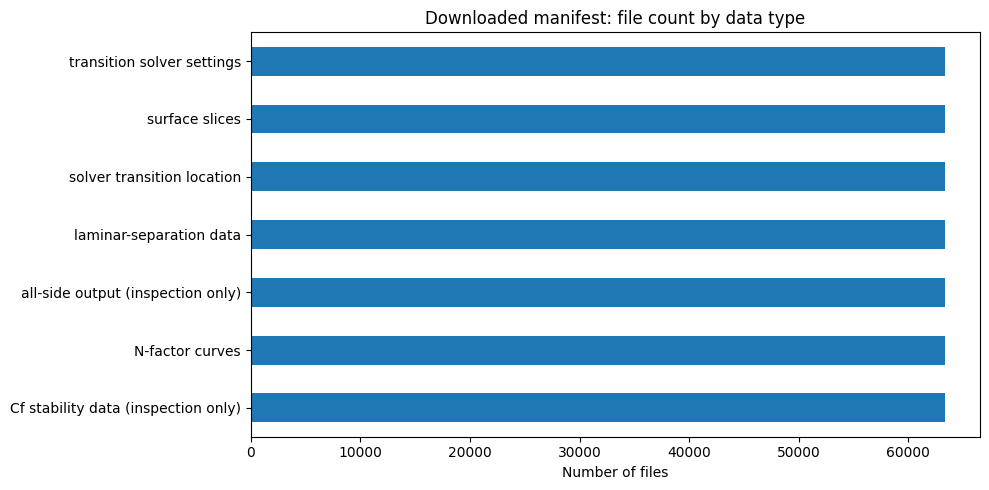

In [12]:
import gzip
import re
import zipfile
from collections import Counter
import matplotlib.pyplot as plt

manifest = pd.read_csv(MANIFEST_PATH, compression="gzip", low_memory=False)
required_columns = {"archive", "name", "bytes", "shard"}
missing_columns = required_columns - set(manifest.columns)
if missing_columns:
    raise ValueError(f"Manifest is missing expected columns: {sorted(missing_columns)}")

CASE_RE = re.compile(r"airfoil_(\d+)_G\d+_[A-Za-z0-9]+_L\d+_case_(\d+)")
def file_kind(name):
    base = Path(str(name)).name.lower()
    if base.endswith("_slices.dat"):
        return "surface slices"
    if base == "transiloc.dat":
        return "solver transition location"
    if base == "nfactor_ts.dat":
        return "N-factor curves"
    if base == "bledge_info.dat":
        return "laminar-separation data"
    if base == "nfactor_cf.dat":
        return "Cf stability data (inspection only)"
    if base == "allsideout.dat":
        return "all-side output (inspection only)"
    if base == "tscf_info.dat":
        return "transition solver settings"
    return Path(base).suffix or "other"

manifest["file_kind"] = manifest["name"].map(file_kind)
manifest["size_MB"] = pd.to_numeric(manifest["bytes"], errors="coerce") / 1e6
manifest["case_match"] = manifest["name"].map(lambda n: bool(CASE_RE.search(str(n))))

print(f"Manifest rows: {len(manifest):,}")
print(f"Unique shard files referenced: {manifest['shard'].nunique():,}")
print(f"Distinct airfoil/case identifiers found in manifest paths: "
      f"{manifest.loc[manifest.case_match, 'name'].map(lambda n: CASE_RE.search(str(n)).groups()).nunique() if manifest.case_match.any() else 0:,}")
display(manifest.head(10))

kind_summary = (manifest.groupby("file_kind", dropna=False)
                .agg(file_count=("name", "size"), total_MB=("size_MB", "sum"))
                .sort_values("file_count", ascending=False))
display(kind_summary)

# Count the analysis/convergence records inside the unchanged archive separately.
with zipfile.ZipFile(WHOLE_ARCHIVE) as whole_zip:
    whole_names = whole_zip.namelist()
analysis_count = sum(Path(n).name.endswith("_analysis.csv") for n in whole_names)
convergence_count = sum(Path(n).name.endswith("_convergence.pkl") for n in whole_names)
whole_summary = pd.DataFrame([
    {"file_kind": "analysis.csv", "file_count": analysis_count},
    {"file_kind": "convergence.pkl", "file_count": convergence_count},
])
print("Files listed in the unchanged simulation archive:")
display(whole_summary)

fig, ax = plt.subplots(figsize=(10, 5))
kind_summary["file_count"].sort_values().plot(kind="barh", ax=ax)
ax.set_title("Downloaded manifest: file count by data type")
ax.set_xlabel("Number of files")
ax.set_ylabel("")
fig.tight_layout()
if SAVE_PLOTS:
    PREP_DIR.mkdir(parents=True, exist_ok=True)
    (PREP_DIR / "visualizations").mkdir(exist_ok=True)
    fig.savefig(PREP_DIR / "visualizations" / "manifest_file_counts.png", dpi=160, bbox_inches="tight")
plt.show()

### 6.1 Check that shard files listed in the manifest exist

This is a file-presence check. It is not a complete checksum re-verification; the downloader already checks extracted entries against their ZIP metadata.

In [13]:
def expected_shard_path(row):
    # Expected layout: raw/<archive basename without .zip>/<shard>
    archive_stem = Path(str(row["archive"])).name[:-4]
    return RAW_DIR / "raw" / archive_stem / str(row["shard"])

unique_shards = manifest[["archive", "shard"]].drop_duplicates().copy()
unique_shards["expected_path"] = unique_shards.apply(expected_shard_path, axis=1)
unique_shards["exists"] = unique_shards["expected_path"].map(lambda p: p.is_file())
print(f"Shard files found: {unique_shards['exists'].sum():,} / {len(unique_shards):,}")
if not unique_shards["exists"].all():
    display(unique_shards.loc[~unique_shards["exists"]].head(20))
else:
    print("All shard paths referenced by the manifest exist.")

Shard files found: 47 / 47
All shard paths referenced by the manifest exist.


### 6.2 CRC-32 spot check of the downloaded files

Step 1 of the chapter: each file was checked against the CRC-32 checksum stored in the original archive when it was downloaded. This cell repeats that check on a random sample of 500 files (fixed seed), reading each file from its shard and comparing its CRC-32 with the value in the manifest.

In [14]:
import zlib

N_CRC_SAMPLE = 500
crc_manifest = pd.read_csv(MANIFEST_PATH, compression="gzip", dtype=str, usecols=["archive", "name", "crc32", "shard"])
crc_sample = crc_manifest.sample(min(N_CRC_SAMPLE, len(crc_manifest)), random_state=SEED)

crc_problems = []
open_shards = {}
for r in crc_sample.itertuples(index=False):
    path = expected_shard_path({"archive": r.archive, "shard": r.shard})
    try:
        if path not in open_shards:
            open_shards[path] = zipfile.ZipFile(path)
        data = open_shards[path].read(r.name)          # zipfile also checks the shard's own CRC-32 here
        crc = f"{zlib.crc32(data) & 0xFFFFFFFF:08x}"
        if crc != str(r.crc32).strip().lower().zfill(8):
            crc_problems.append((r.name, "CRC-32 differs from the original archive"))
    except Exception as error:
        crc_problems.append((r.name, f"could not be read: {error}"))
for z in open_shards.values():
    z.close()

print(f"Files checked: {len(crc_sample):,}; CRC-32 matches the original archive: {len(crc_sample) - len(crc_problems):,}")
if crc_problems:
    display(pd.DataFrame(crc_problems, columns=["file", "problem"]).head(20))

Files checked: 500; CRC-32 matches the original archive: 500


## 7. Run the preprocessing (methodology steps 2 to 7)

This cell runs the pipeline of Section 4 on all cases and writes the prepared dataset to `prepared/`. Batches that are already finished are reused, so a stopped run carries on where it stopped; with every batch finished, it only screens the cases again, rewrites `cases.csv` and the report, and runs the checks of Section 4.6.

Refresh options (normally `False`):
- `REDO_SOLVER_ENVELOPE = True` once, if the `prepared` folder was made by the earlier version of this notebook: it adds the solver's own envelope (step 5) by reading `nfactor_ts.dat` again. This takes some time; finished batches are skipped if it is stopped and run again.
- `REDO_CONVERGENCE` or `REDO_NFACTOR`: only to refresh those extracted fields.

In [15]:
# These options are normally left False. They refresh fields in existing saved case batches.
REDO_CONVERGENCE = False
REDO_NFACTOR = False
REDO_SOLVER_ENVELOPE = False   # True once for a prepared folder made by the earlier version of this notebook

if RUN_PREPROCESS:
    prepared_table, actual_output_dir = run_preprocessing(
        raw_dir=RAW_DIR,
        out_base_dir=PREP_BASE_DIR,
        max_cases=MAX_CASES,
        redo_convergence=REDO_CONVERGENCE,
        redo_nfactor=REDO_NFACTOR,
        redo_solver_envelope=REDO_SOLVER_ENVELOPE,
    )
    PREP_DIR = Path(actual_output_dir)
else:
    print("RUN_PREPROCESS=False: skipping processing and reading existing prepared outputs.")
    PREP_DIR = PREP_BASE_DIR / (f"try_{MAX_CASES}" if MAX_CASES is not None else "")

VIS_DIR = PREP_DIR / "visualizations"
VIS_DIR.mkdir(parents=True, exist_ok=True)
CASES_PATH = PREP_DIR / "cases.csv"
print("Prepared output folder:", PREP_DIR)
if not CASES_PATH.is_file():
    raise FileNotFoundError(
        f"Cannot find {CASES_PATH}. Set RUN_PREPROCESS=True or point PREP_DIR at an existing prepared run."
    )

Finding files for each case ...
Cases selected for this run: 63,373
PREPROCESSING REPORT

cases: 63,373 on 4,618 airfoils
kept for RQ1 (drag, crossover):      63,372 (100.0%)
kept for RQ2 (also transition valid): 63,078 (99.5%)
RQ1 sensitivity subset (also steady CD history): 19,162 (30.2%)

settings (fixed before the run; methodology Tables 3.4 and 3.6):
  converged = total residual fell by at least 6 orders of magnitude.
  Own choice, fixed in advance, because UniFoil does not publish its stopping rule;
  a looser rule of 5 orders is compared below as a sensitivity check.
  sensitivity only: CD in the saved history changed by at most 0.1% over the last
  10 % of iterations (our choice; used only for keep_rq1_strict, never to remove cases)
  at least 50 slice points on each surface
  RQ1 needs: analysis, convergence, slices   RQ2 also needs: transiLoc.dat
  e^N cross-check only (reported, not removed): nfactor_ts.dat, bledge_info.dat

run environment:
  dataset revision: 6724bb9691e86

In [16]:
import pandas as pd
import numpy as np

# Define 'cases' from the previously prepared table variable
cases = prepared_table

# Inspect the actual residual drop distribution and raw values
if 'residual_drop_orders' in cases:
    print("--- Summary statistics of residual_drop_orders ---")
    display(cases['residual_drop_orders'].describe())

    print("\n--- First 10 raw residual drop values ---")
    display(cases[['airfoil', 'case', 'residual_drop_orders', 'n_iter', 'cd_tail_rel_change']].head(10))

    # Count how many are NaN or null
    missing_residuals = cases['residual_drop_orders'].isna().sum()
    print(f"\nNumber of cases with missing/NaN residuals: {missing_residuals} / {len(cases)}")
else:
    print("The column 'residual_drop_orders' is missing from the cases DataFrame.")

--- Summary statistics of residual_drop_orders ---


,residual_drop_orders
count,63373.000000
mean,6.131135
std,0.085332
min,6.000005
25%,6.056108
50%,6.120750
75%,6.204576
max,6.389653



--- First 10 raw residual drop values ---


,airfoil,case,residual_drop_orders,n_iter,cd_tail_rel_change
0,1,0,6.165095,25,0.002129
1,1,1,6.141248,37,0.002068
2,1,2,6.014686,40,0.000901
3,1,3,6.215444,25,0.001266
4,1,4,6.049811,23,0.003097
5,1,5,6.032911,60,0.004619
6,1,6,6.061142,27,0.001145
7,1,7,6.141912,27,0.003099
8,1,8,6.077244,29,0.004116
9,1,9,6.199059,25,0.002104



Number of cases with missing/NaN residuals: 0 / 63373


## 8. Load and summarise the prepared case table

In [17]:
cases = pd.read_csv(CASES_PATH, low_memory=False)
print(f"Prepared cases: {len(cases):,}")
print(f"Distinct airfoils: {cases['airfoil'].nunique():,}" if "airfoil" in cases else "No airfoil column found.")
print(f"Columns: {len(cases.columns)}")
display(cases.head(8))

# Convert keep/flag columns robustly if pandas read them as strings.
def to_bool_value(value):
    if pd.isna(value):
        return False
    if isinstance(value, (bool, np.bool_)):
        return bool(value)
    return str(value).strip().lower() in {"true", "1", "1.0", "yes"}

for col in ["keep_rq1", "keep_rq2", "keep_rq1_strict"]:
    if col in cases:
        cases[col] = cases[col].map(to_bool_value)

summary_rows = []
for col, label in [("keep_rq1", "Kept for RQ1"), ("keep_rq2", "Kept for RQ2"), ("keep_rq1_strict", "Strict RQ1 subset")]:
    if col in cases:
        count = int(cases[col].sum())
        summary_rows.append({"selection": label, "kept": count, "not_kept_from_all_cases": len(cases)-count,
                             "kept_percent": 100 * count / len(cases) if len(cases) else np.nan})
display(pd.DataFrame(summary_rows))

Prepared cases: 63,373
Distinct airfoils: 4,618
Columns: 56


,airfoil,case,missing_files,Mach,AoA_stated,Re,CL_reported,CD_reported,slice_ok,n_points_upper,...,flag_transition_missing_lower,flag_transition_placeholder_lower,flag_bad_frequency_lower,flag_en_check_file_missing,flag_cd_history_unsteady,keep_rq1,keep_rq2,keep_rq1_strict,removed_from_rq1_because,removed_from_rq2_because
0,1,0,NaN,0.339795,2.724399,2890000.0,-0.000422,0.008874,True,148,...,False,False,False,False,True,True,True,False,NaN,NaN
1,1,1,NaN,0.690023,0.755782,1300000.0,-0.001137,0.086182,True,148,...,False,False,False,False,True,True,True,False,NaN,NaN
2,1,2,NaN,0.664469,1.786138,5170000.0,-0.005771,0.185051,True,148,...,False,False,False,False,False,True,True,True,NaN,NaN
3,1,3,NaN,0.190151,2.520059,1330000.0,-0.000464,0.010549,True,148,...,False,False,False,False,True,True,True,False,NaN,NaN
4,1,4,NaN,0.261451,5.818668,1040000.0,-0.001050,0.010306,True,148,...,False,False,False,False,True,True,True,False,NaN,NaN
5,1,5,NaN,0.567517,0.141196,2930000.0,-0.000025,0.010064,True,148,...,False,False,False,False,True,True,True,False,NaN,NaN
6,1,6,NaN,0.348620,3.700253,6840000.0,-0.000550,0.008503,True,148,...,False,False,False,False,True,True,True,False,NaN,NaN
7,1,7,NaN,0.427258,4.635979,5610000.0,-0.000648,0.007992,True,148,...,False,False,False,False,True,True,True,False,NaN,NaN


,selection,kept,not_kept_from_all_cases,kept_percent
0,Kept for RQ1,63372,1,99.998422
1,Kept for RQ2,63078,295,99.534502
2,Strict RQ1 subset,19162,44211,30.236852


## 9. Hand inspection of a random sample of flagged and unflagged cases

Methodology Section 3.5, *Checks*: a random sample of flagged and unflagged cases, drawn with a fixed seed, is inspected by hand to confirm that each flag was set correctly. For every flag that removes cases, up to 3 flagged cases are drawn, plus 5 cases with no removal flag (seed 2026).

The first table shows each sampled case with the values its flags are based on. `evidence_agrees` repeats each rule from these values; it is a help for the inspection, not a replacement. The second cell prints the raw-file evidence of each sampled case (missing files, the lines of `transiLoc.dat`, and any unreadable `****` zones in `nfactor_ts.dat`). The sample is saved as `flag_inspection_sample.csv` with an empty column `checked_by_hand` for your notes.

In [18]:
REMOVAL_FLAGS = ["rq1_file_missing", "not_converged", "bad_surface_data", "cd_not_positive",
                 "transition_file_missing", "transition_missing_upper", "transition_missing_lower",
                 "transition_placeholder_upper", "transition_placeholder_lower",
                 "bad_frequency_upper", "bad_frequency_lower"]

samples = []
for flag in REMOVAL_FLAGS:
    col = "flag_" + flag
    if col in cases:
        flagged = cases[cases[col].map(to_bool_value)]
        if len(flagged):
            samples.append(flagged.sample(min(3, len(flagged)), random_state=SEED).assign(sampled_for=flag))
unflagged = cases[cases["keep_rq2"]]
samples.append(unflagged.sample(min(5, len(unflagged)), random_state=SEED).assign(sampled_for="no removal flag"))
inspection = pd.concat(samples, ignore_index=True)


def rule_from_evidence(row, flag):
    """the rule of Table 3.4, worked out again from the values in the row (None = needs the raw file)"""
    missing = str(row.get("missing_files", "") if pd.notna(row.get("missing_files", "")) else "")
    x_up, x_lo = row.get("x_tr_solver_upper", np.nan), row.get("x_tr_solver_lower", np.nan)
    rules = {
        "rq1_file_missing": any(n in missing.split(",") for n in RQ1_FILES),
        "not_converged": not (row.get("residual_drop_orders", np.nan) >= RESIDUAL_DROP_MIN),
        "bad_surface_data": (not to_bool_value(row.get("slice_ok", False)))
                            or not (row.get("n_points_upper", 0) >= MIN_SURFACE_POINTS)
                            or not (row.get("n_points_lower", 0) >= MIN_SURFACE_POINTS),
        "cd_not_positive": row.get("CD_reported", np.nan) <= 0,
        "transition_file_missing": "transiLoc.dat" in missing.split(","),
        "transition_missing_upper": pd.isna(x_up),
        "transition_missing_lower": pd.isna(x_lo),
        "transition_placeholder_upper": pd.notna(x_up) and not (0 <= x_up <= 1),
        "transition_placeholder_lower": pd.notna(x_lo) and not (0 <= x_lo <= 1),
        "bad_frequency_upper": None,
        "bad_frequency_lower": None,
    }
    if flag == "no removal flag":                     # an unflagged case must break no rule
        return not any(v for v in rules.values() if v is not None)
    return rules[flag]


inspection["evidence_agrees"] = [rule_from_evidence(r, r["sampled_for"]) for _, r in inspection.iterrows()]
evidence_cols = ["sampled_for", "airfoil", "case", "evidence_agrees", "missing_files", "residual_drop_orders",
                 "slice_ok", "n_points_upper", "n_points_lower", "CD_reported", "x_tr_solver_upper",
                 "x_tr_solver_lower", "bad_frequency_upper", "bad_frequency_lower",
                 "removed_from_rq1_because", "removed_from_rq2_because"]
evidence_cols = [c for c in evidence_cols if c in inspection]
inspection["checked_by_hand"] = ""
inspection[evidence_cols + ["checked_by_hand"]].to_csv(PREP_DIR / "flag_inspection_sample.csv", index=False)
print(f"Sampled cases: {len(inspection)} (saved as flag_inspection_sample.csv)")
display(inspection[evidence_cols])

Sampled cases: 16 (saved as flag_inspection_sample.csv)


,sampled_for,airfoil,case,evidence_agrees,missing_files,residual_drop_orders,slice_ok,n_points_upper,n_points_lower,CD_reported,x_tr_solver_upper,x_tr_solver_lower,bad_frequency_upper,bad_frequency_lower,removed_from_rq1_because,removed_from_rq2_because
0,rq1_file_missing,6513,8,True,analysis,6.280519,True,148,158,NaN,0.541250,0.510270,False,False,rq1_file_missing,rq1_file_missing
1,transition_placeholder_upper,6314,4,True,NaN,6.236509,True,147,159,0.007533,7.000000,6.021726,False,False,NaN,"transition_placeholder_upper,transition_placeh..."
2,transition_placeholder_upper,6993,6,True,NaN,6.032455,True,148,158,0.007842,6.289521,7.000000,False,False,NaN,"transition_placeholder_upper,transition_placeh..."
3,transition_placeholder_upper,3961,1,True,NaN,6.000245,True,147,159,0.233565,6.299448,6.327162,False,False,NaN,"transition_placeholder_upper,transition_placeh..."
4,transition_placeholder_lower,6314,4,True,NaN,6.236509,True,147,159,0.007533,7.000000,6.021726,False,False,NaN,"transition_placeholder_upper,transition_placeh..."
5,transition_placeholder_lower,6993,6,True,NaN,6.032455,True,148,158,0.007842,6.289521,7.000000,False,False,NaN,"transition_placeholder_upper,transition_placeh..."
6,transition_placeholder_lower,3961,1,True,NaN,6.000245,True,147,159,0.233565,6.299448,6.327162,False,False,NaN,"transition_placeholder_upper,transition_placeh..."
7,bad_frequency_upper,4254,7,None,NaN,6.097938,True,149,157,0.072709,0.259982,0.017049,True,False,NaN,bad_frequency_upper
8,bad_frequency_upper,1522,11,None,NaN,6.286396,True,148,158,0.017914,0.537550,0.032215,True,False,NaN,bad_frequency_upper
9,bad_frequency_upper,6764,0,None,NaN,6.105662,True,149,157,0.055492,0.282343,0.212215,True,False,NaN,bad_frequency_upper


In [19]:
# Raw-file evidence of every sampled case (read only; the raw files are not changed)
inspect_files = find_files(str(RAW_DIR))
inspect_store = Store(str(RAW_DIR))
for _, r in inspection.iterrows():
    key = (int(r["airfoil"]), int(r["case"]))
    where = inspect_files.get(key, {})
    print(f"--- airfoil {key[0]}, case {key[1]} (sampled for: {r['sampled_for']})")
    missing = [n for n in RQ1_FILES + RQ2_FILES + CHECK_FILES if n not in where]
    print("    missing files:", ", ".join(missing) if missing else "none")
    if "transiLoc.dat" in where:
        lines = inspect_store.shard(*where["transiLoc.dat"]).decode("utf-8", "replace").strip().splitlines()
        print("    transiLoc.dat:", " | ".join(l.strip() for l in lines[:2]))
    if "nfactor_ts.dat" in where:
        text = inspect_store.shard(*where["nfactor_ts.dat"]).decode("utf-8", "replace")
        starred = [l.strip() for l in text.splitlines() if l.strip().lower().startswith("zone") and "*" in l]
        print(f"    nfactor_ts.dat zones with '****': {len(starred)}" + (f", e.g. {starred[0][:90]}" if starred else ""))

--- airfoil 6513, case 8 (sampled for: rq1_file_missing)
    missing files: analysis
    transiLoc.dat: 0.54125004589884540        8.0689385565554855E-002  0.50000000000000000        5.9173823701738647E-002 | 0.51027016538193803       -5.4559004267640390E-002  0.50000000000000000        5.7914529281164445E-002
    nfactor_ts.dat zones with '****': 0
--- airfoil 6314, case 4 (sampled for: transition_placeholder_upper)
    missing files: none
    transiLoc.dat: 7.0000000000000000        3.0229264989167628E-002  0.50000000000000000       -6.0099999999999998 | 6.0217259508708549       -3.0628291011211620E-002  0.50000000000000000       -5.0317259508708547
    nfactor_ts.dat zones with '****': 0
--- airfoil 6993, case 6 (sampled for: transition_placeholder_upper)
    missing files: none
    transiLoc.dat: 6.2895207184533204        5.5281041776046425E-002  0.50000000000000000       -5.2995207184533202 | 7.0000000000000000        3.4288603893095509E-003  0.50000000000000000       -6.009999999

## 10. Angle-of-attack check (methodology Section 3.5)

The drag split needs the incidence actually used in each run, so the stated AoA is checked in two ways before the drag split.

**Test 1 (all cases):** thin-airfoil theory gives a lift slope of about 2π per radian, increased at higher Mach number by the Prandtl–Glauert factor 1/√(1 − M²), so the stored lift should rise clearly with the stated angle. For each lift source (`CL_reported` from `analysis.csv`, and the solver's last lift `cl_solver` from `convergence.pkl` where available), the cell finds:
- the slope of stored lift against the thin-airfoil lift 2π·α/√(1 − M²), using only differences between cases of the same airfoil (this removes each airfoil's own zero-lift angle, for example from camber). A slope of 1 means lift rises as thin-airfoil theory says; 0 means it does not rise with the stated angle;
- the rank correlation between stored lift and stated angle;
- for information, the share of cases where the stored lift equals −CD·tan(AoA), which is what a force with no component across the chord, turned by the stated angle, would give.

**Test 2 (12 cases):** for twelve cases spread over the AoA range, the volume solution is read with PyVista and the direction of the flow far from the airfoil is compared with the stated angle (Section 10.2).

As the chapter says, the stated AoA is used as stated only if both tests confirm it; otherwise the drag direction is set from the incidence found in the volume solutions, AoA is left out of RO2 and of the matching in RQ2, and the mismatch is reported to the supervisor and the dataset authors.

,lift source,cases,airfoils,slope vs thin-airfoil lift,rank correlation with stated AoA,share with lift = -CD*tan(AoA)
0,CL_reported,63359,4610,-0.0025,-0.8968,1.0000
1,cl_solver,63359,4610,-0.0026,-0.9186,0.0045


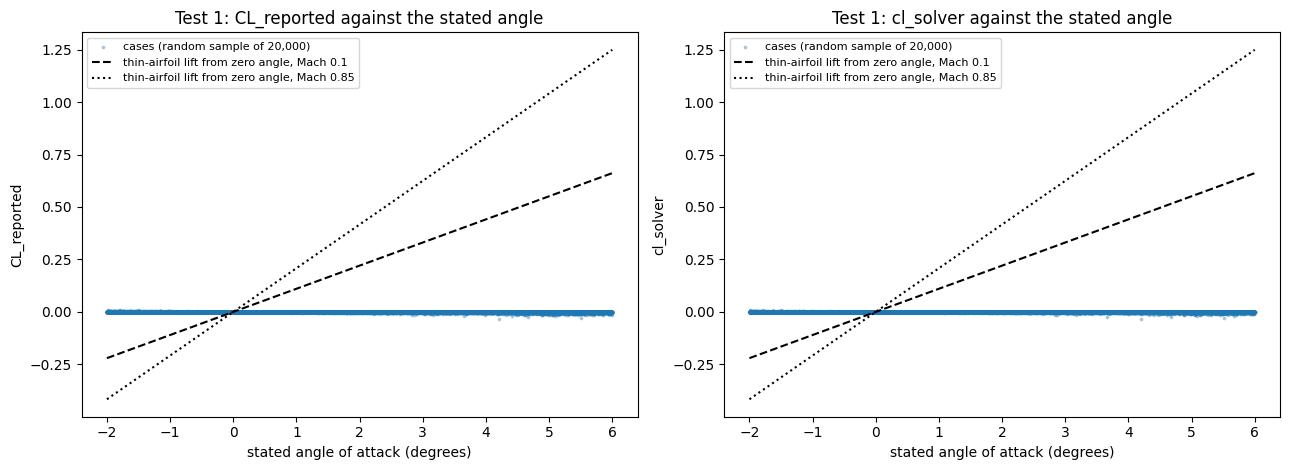

In [20]:
# 10.1 Test 1: does the stored lift rise with the stated angle? (all cases kept for RQ1)
aoa_cases = cases[cases["keep_rq1"]].copy()
for col in ["AoA_stated", "Mach", "CL_reported", "CD_reported", "cl_solver"]:
    if col in aoa_cases:
        aoa_cases[col] = pd.to_numeric(aoa_cases[col], errors="coerce")
alpha = np.radians(aoa_cases["AoA_stated"])
aoa_cases["thin_airfoil_cl"] = 2 * np.pi * alpha / np.sqrt(1 - aoa_cases["Mach"] ** 2)


def within_airfoil_slope(df, lift_col):
    """slope of stored lift against thin-airfoil lift, from differences between cases of the same airfoil"""
    d = df[["airfoil", lift_col, "thin_airfoil_cl"]].dropna()
    d = d[d.groupby("airfoil")["airfoil"].transform("size") >= 3]
    x = d["thin_airfoil_cl"] - d.groupby("airfoil")["thin_airfoil_cl"].transform("mean")
    y = d[lift_col] - d.groupby("airfoil")[lift_col].transform("mean")
    return float((x * y).sum() / (x * x).sum()), len(d), d["airfoil"].nunique()


lift_sources = [c for c in ["CL_reported", "cl_solver"] if c in aoa_cases and aoa_cases[c].notna().any()]
rows = []
for col in lift_sources:
    slope, n_cases, n_airfoils = within_airfoil_slope(aoa_cases, col)
    both = aoa_cases[[col, "AoA_stated", "CD_reported"]].dropna()
    rotated_drag = -both["CD_reported"] * np.tan(np.radians(both["AoA_stated"]))
    rows.append({"lift source": col, "cases": n_cases, "airfoils": n_airfoils,
                 "slope vs thin-airfoil lift": slope,
                 "rank correlation with stated AoA": both[col].rank().corr(both["AoA_stated"].rank()),
                 "share with lift = -CD*tan(AoA)": float(np.isclose(both[col], rotated_drag, rtol=1e-3, atol=1e-7).mean())})
aoa_test1 = pd.DataFrame(rows)
aoa_test1.to_csv(PREP_DIR / "aoa_check_test1.csv", index=False)
display(aoa_test1.round(4))

if not lift_sources:
    raise ValueError("No stored lift coefficient found (CL_reported or cl_solver), so test 1 cannot be done.")
fig, axes = plt.subplots(1, len(lift_sources), figsize=(6.5 * len(lift_sources), 4.8), squeeze=False)
shown = aoa_cases.sample(min(20000, len(aoa_cases)), random_state=SEED)
angles = np.linspace(-2, 6, 50)
for ax, col in zip(axes[0], lift_sources):
    ax.scatter(shown["AoA_stated"], shown[col], s=3, alpha=0.3, label=f"cases (random sample of {len(shown):,})")
    for m, style in [(0.1, "--"), (0.85, ":")]:
        ax.plot(angles, 2 * np.pi * np.radians(angles) / np.sqrt(1 - m ** 2), style, color="black",
                label=f"thin-airfoil lift from zero angle, Mach {m}")
    ax.set_xlabel("stated angle of attack (degrees)")
    ax.set_ylabel(col)
    ax.set_title(f"Test 1: {col} against the stated angle")
    ax.legend(fontsize=8)
fig.tight_layout()
if SAVE_PLOTS:
    fig.savefig(PREP_DIR / "visualizations" / "aoa_check_test1.png", dpi=160, bbox_inches="tight")
plt.show()

### 10.2 Test 2: flow direction far from the airfoil in 12 volume solutions

Twelve cases kept for RQ1 are chosen with the fixed seed, one from each of 12 equal bands of the stated AoA, so that they are spread over the AoA range. Their volume files (`*_vol.cgns`, about 8 MB each) are not part of the main download, so the next cell looks them up in the archive indexes saved by the download script (`raw_data/index/`), downloads only those 12 files from the pinned revision with byte-range requests, and checks each against its CRC-32, as in step 1. They are saved in `raw_data/volume_sample/`; the raw files already downloaded are not touched. The cell after that reads each file with PyVista and compares the flow direction far from the airfoil with the stated angle.

In [21]:
# 10.2a Choose the 12 cases and fetch their volume files
import json
import struct
import zlib
import requests

N_VOLUME_CASES = 12
VOLUME_DIR = RAW_DIR / "volume_sample"
REPO_ID = "rkanchi/UniFoil"
FULL_REVISION = "6724bb9691e866655446543aa3ee16cf78f26b5f"   # commit 6724bb9 (methodology Table 3.6)

kept = cases[cases["keep_rq1"]].copy()
kept["aoa_band"] = pd.cut(pd.to_numeric(kept["AoA_stated"], errors="coerce"), N_VOLUME_CASES)
volume_cases = (kept.groupby("aoa_band", observed=True).sample(1, random_state=SEED)
                [["airfoil", "case", "Mach", "AoA_stated"]].reset_index(drop=True))
wanted = {(int(a), int(c)) for a, c in zip(volume_cases.airfoil, volume_cases.case)}

# Find the 12 volume files in the archive indexes written by the download script
entries = {}
for index_csv in sorted((RAW_DIR / "index").glob("*.csv.gz")):
    meta_path = Path(str(index_csv)[:-len(".csv.gz")] + ".json")
    if not meta_path.is_file():
        continue
    archive_rel = json.load(open(meta_path))["archive"]
    index = pd.read_csv(index_csv, compression="gzip", dtype={"name": str})
    for r in index[index["name"].str.endswith("_vol.cgns")].itertuples(index=False):
        m = CASE_RE.search(r.name)
        if m and (int(m.group(1)), int(m.group(2))) in wanted:
            entries[(int(m.group(1)), int(m.group(2)))] = (archive_rel, r._asdict())


def fetch_member(archive_rel, e):
    """one file out of a remote zip archive, by byte range, checked against its CRC-32 (as in step 1)"""
    url = f"https://huggingface.co/datasets/{REPO_ID}/resolve/{FULL_REVISION}/{archive_rel}"
    headers = {"User-Agent": "UniFoil-research/1.0"}
    if os.environ.get("HF_TOKEN"):
        headers["Authorization"] = f"Bearer {os.environ['HF_TOKEN']}"

    def get(start, length):
        r = requests.get(url, headers={**headers, "Range": f"bytes={start}-{start + length - 1}"},
                         timeout=180, allow_redirects=True)
        if r.status_code != 206:
            raise IOError(f"HTTP {r.status_code} for {archive_rel}")
        return r.content
    offset, csize = int(e["offset"]), int(e["csize"])
    head = get(offset, 30)
    if struct.unpack("<I", head[:4])[0] != 0x04034B50:
        raise IOError(f"no zip entry at the indexed position of {e['name']}")
    name_len, extra_len = struct.unpack("<HH", head[26:30])
    data = get(offset + 30 + name_len + extra_len, csize)
    raw = zlib.decompress(data, -15) if int(e["method"]) == 8 else data
    if (zlib.crc32(raw) & 0xFFFFFFFF) != int(e["crc"]):
        raise IOError(f"CRC-32 mismatch in {e['name']}")
    return raw


VOLUME_DIR.mkdir(parents=True, exist_ok=True)
volume_cases["volume_file"] = ""
for i, r in volume_cases.iterrows():
    key = (int(r.airfoil), int(r.case))
    if key not in entries:
        print(f"airfoil {key[0]}, case {key[1]}: no *_vol.cgns file in the archive indexes")
        continue
    archive_rel, e = entries[key]
    target = VOLUME_DIR / Path(e["name"]).name
    if not target.is_file():
        tmp = Path(str(target) + ".part")
        tmp.write_bytes(fetch_member(archive_rel, e))
        os.replace(tmp, target)
    volume_cases.loc[i, "volume_file"] = str(target)
print(f"Volume files ready: {(volume_cases.volume_file != '').sum()} of {len(volume_cases)}")
display(volume_cases)

Volume files ready: 12 of 12


,airfoil,case,Mach,AoA_stated,volume_file
0,2418,4,0.230194,-1.639772,/content/drive/MyDrive/unifoil_project/raw_dat...
1,2200,4,0.440949,-1.304069,/content/drive/MyDrive/unifoil_project/raw_dat...
2,6121,10,0.265983,-0.662487,/content/drive/MyDrive/unifoil_project/raw_dat...
3,6295,12,0.346263,0.221886,/content/drive/MyDrive/unifoil_project/raw_dat...
4,2168,2,0.765534,1.115710,/content/drive/MyDrive/unifoil_project/raw_dat...
5,1652,8,0.405803,1.804567,/content/drive/MyDrive/unifoil_project/raw_dat...
6,1169,11,0.367372,2.451295,/content/drive/MyDrive/unifoil_project/raw_dat...
7,1293,4,0.807718,2.923385,/content/drive/MyDrive/unifoil_project/raw_dat...
8,5340,6,0.374354,3.753266,/content/drive/MyDrive/unifoil_project/raw_dat...
9,2027,4,0.786131,4.603691,/content/drive/MyDrive/unifoil_project/raw_dat...


In [22]:
# 10.2b Read each volume file with PyVista and find the flow direction far from the airfoil
if importlib.util.find_spec("pyvista") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "pyvista"])
import pyvista as pv


def leaf_blocks(data):
    """all meshes inside a (nested) PyVista MultiBlock"""
    if isinstance(data, pv.MultiBlock):
        for block in data:
            if block is not None:
                yield from leaf_blocks(block)
    elif data is not None and data.n_points > 0:
        yield data


def flow_arrays(mesh):
    """(positions, velocity) from cell or point data; velocity from VelocityX/Y/Z or Momentum/Density"""
    for kind, data, positions in (("cell", mesh.cell_data, lambda: mesh.cell_centers().points),
                                  ("point", mesh.point_data, lambda: mesh.points)):
        names = {n.lower(): n for n in data.keys()}
        if all(f"velocity{a}" in names for a in "xyz"):
            v = np.column_stack([np.asarray(data[names[f"velocity{a}"]], dtype=float) for a in "xyz"])
            return positions(), v
        if all(f"momentum{a}" in names for a in "xyz") and "density" in names:
            rho = np.asarray(data[names["density"]], dtype=float)
            v = np.column_stack([np.asarray(data[names[f"momentum{a}"]], dtype=float) / rho for a in "xyz"])
            return positions(), v
    return None, None


def far_field_angle(path, far_share=0.10):
    """flow angle (degrees) of the outer 10 % of the cells, measured from the x-axis in the airfoil's plane"""
    try:
        reader = pv.get_reader(str(path))
        for method in ("enable_all_cell_arrays", "enable_all_point_arrays"):
            if hasattr(reader, method):
                getattr(reader, method)()
        data = reader.read()
    except Exception:
        data = pv.read(str(path))
    positions, velocities, fields = [], [], set()
    for mesh in leaf_blocks(data):
        fields |= set(mesh.cell_data.keys()) | set(mesh.point_data.keys())
        p, v = flow_arrays(mesh)
        if p is not None:
            positions.append(p)
            velocities.append(v)
    if not positions:
        raise ValueError(f"no velocity or momentum fields found; fields in the file: {sorted(fields)[:20]}")
    p, v = np.vstack(positions), np.vstack(velocities)
    # the airfoil's plane: x and whichever of y or z spreads more (the other one is the span)
    up = 1 if np.ptp(p[:, 1]) >= np.ptp(p[:, 2]) else 2
    distance = np.hypot(p[:, 0] - 0.5, p[:, up])
    far = distance >= np.quantile(distance, 1 - far_share)
    return float(np.degrees(np.arctan2(v[far, up].mean(), v[far, 0].mean()))), "xy"[0] + "yz"[up - 1]


rows = []
for r in volume_cases.itertuples(index=False):
    if not r.volume_file:
        continue
    try:
        angle, plane = far_field_angle(r.volume_file)
        rows.append({"airfoil": r.airfoil, "case": r.case, "Mach": r.Mach, "stated AoA": r.AoA_stated,
                     "far-field flow angle": angle, "difference (deg)": angle - r.AoA_stated, "plane": plane})
    except Exception as error:
        rows.append({"airfoil": r.airfoil, "case": r.case, "Mach": r.Mach, "stated AoA": r.AoA_stated,
                     "far-field flow angle": np.nan, "difference (deg)": np.nan, "plane": f"not read: {error}"})
aoa_test2 = pd.DataFrame(rows)
aoa_test2.to_csv(PREP_DIR / "aoa_check_test2.csv", index=False)
display(aoa_test2.round(3))

if len(aoa_test2) and aoa_test2["far-field flow angle"].notna().any():
    fig, ax = plt.subplots(figsize=(6, 5))
    ax.scatter(aoa_test2["stated AoA"], aoa_test2["far-field flow angle"], s=40)
    ax.plot([-2, 6], [-2, 6], color="black", linewidth=1, label="same angle")
    ax.set_xlabel("stated angle of attack (degrees)")
    ax.set_ylabel("flow angle far from the airfoil (degrees)")
    ax.set_title("Test 2: stated angle against the flow direction")
    ax.legend()
    fig.tight_layout()
    if SAVE_PLOTS:
        fig.savefig(PREP_DIR / "visualizations" / "aoa_check_test2.png", dpi=160, bbox_inches="tight")
    plt.show()

,airfoil,case,Mach,stated AoA,far-field flow angle,difference (deg),plane
0,2418,4,0.230,-1.640,NaN,NaN,not read: no velocity or momentum fields found...
1,2200,4,0.441,-1.304,NaN,NaN,not read: no velocity or momentum fields found...
2,6121,10,0.266,-0.662,NaN,NaN,not read: no velocity or momentum fields found...
3,6295,12,0.346,0.222,NaN,NaN,not read: no velocity or momentum fields found...
4,2168,2,0.766,1.116,NaN,NaN,not read: no velocity or momentum fields found...
5,1652,8,0.406,1.805,NaN,NaN,not read: no velocity or momentum fields found...
6,1169,11,0.367,2.451,NaN,NaN,not read: no velocity or momentum fields found...
7,1293,4,0.808,2.923,NaN,NaN,not read: no velocity or momentum fields found...
8,5340,6,0.374,3.753,NaN,NaN,not read: no velocity or momentum fields found...
9,2027,4,0.786,4.604,NaN,NaN,not read: no velocity or momentum fields found...


## 11. Visualisation: how many cases are kept?

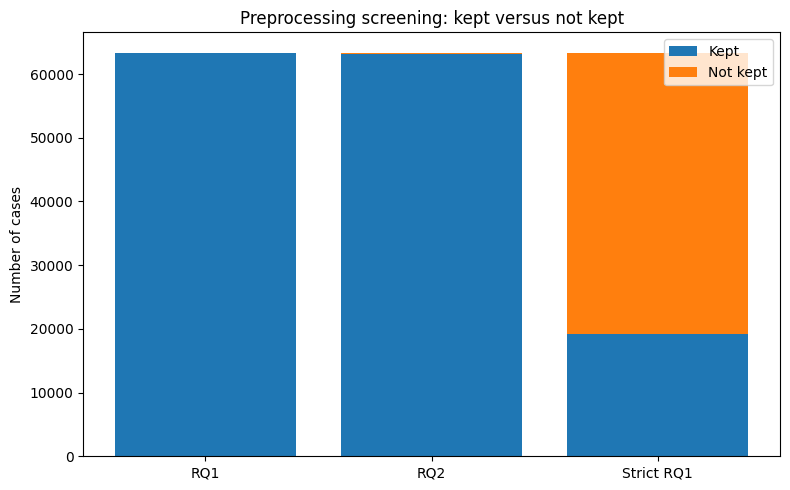

In [23]:
selection_labels, kept_counts, excluded_counts = [], [], []
for col, label in [("keep_rq1", "RQ1"), ("keep_rq2", "RQ2"), ("keep_rq1_strict", "Strict RQ1")]:
    if col in cases:
        selection_labels.append(label)
        kept_counts.append(int(cases[col].sum()))
        excluded_counts.append(int((~cases[col]).sum()))

fig, ax = plt.subplots(figsize=(8, 5))
xpos = np.arange(len(selection_labels))
ax.bar(xpos, kept_counts, label="Kept")
ax.bar(xpos, excluded_counts, bottom=kept_counts, label="Not kept")
ax.set_xticks(xpos, selection_labels)
ax.set_ylabel("Number of cases")
ax.set_title("Preprocessing screening: kept versus not kept")
ax.legend()
fig.tight_layout()
if SAVE_PLOTS:
    fig.savefig(PREP_DIR / "visualizations" / "screening_kept_vs_notkept.png", dpi=160, bbox_inches="tight")
plt.show()

## 12. Visualisation: flags and reasons for exclusion

Several flags can apply to the same case, so the bar heights below can overlap. Also, some flags are informational only; the preprocessing report defines which flags remove a case from each research-question subset.

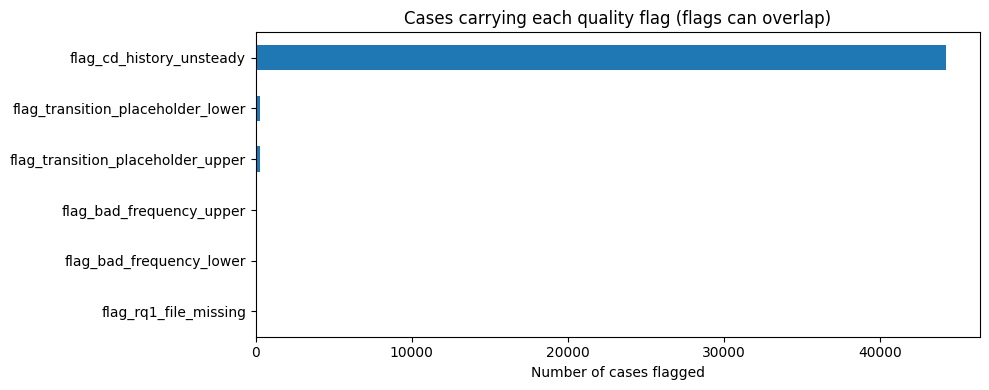

Most common removed_from_rq1_because combinations:


,cases
reason combination,
Kept,63372
rq1_file_missing,1


Most common removed_from_rq2_because combinations:


,cases
reason combination,
Kept,63078
"transition_placeholder_upper,transition_placeholder_lower",283
bad_frequency_upper,10
bad_frequency_lower,1
rq1_file_missing,1


In [24]:
flag_cols = [c for c in cases.columns if c.startswith("flag_")]
if flag_cols:
    flag_counts = cases[flag_cols].apply(lambda s: s.map(to_bool_value).sum()).sort_values(ascending=True)
    flag_counts = flag_counts[flag_counts > 0]
    fig, ax = plt.subplots(figsize=(10, max(4, 0.38 * len(flag_counts))))
    flag_counts.plot(kind="barh", ax=ax)
    ax.set_title("Cases carrying each quality flag (flags can overlap)")
    ax.set_xlabel("Number of cases flagged")
    ax.set_ylabel("")
    fig.tight_layout()
    if SAVE_PLOTS:
        fig.savefig(PREP_DIR / "visualizations" / "quality_flags.png", dpi=160, bbox_inches="tight")
    plt.show()
else:
    print("No flag_* columns found in cases.csv.")

for col in ["removed_from_rq1_because", "removed_from_rq2_because"]:
    if col in cases:
        counts = (cases[col].fillna("").astype(str).replace("", "Kept")
                  .value_counts().head(15))
        print(f"Most common {col} combinations:")
        display(counts.rename_axis("reason combination").to_frame("cases"))

## 13. Visualisation: flight-condition distributions

These are distributions of cases in the prepared table. If this is the 300-case trial, the plots describe only that subset, not the complete UniFoil dataset.

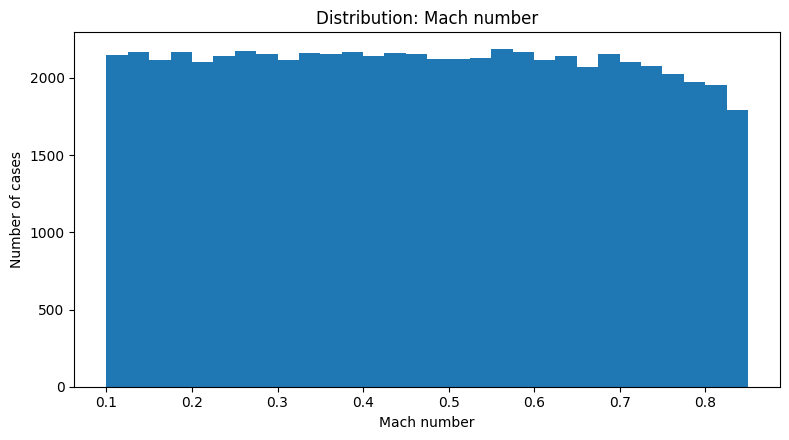

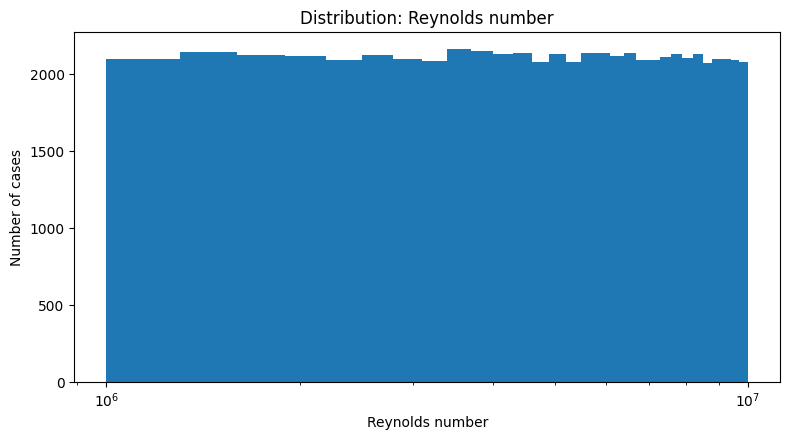

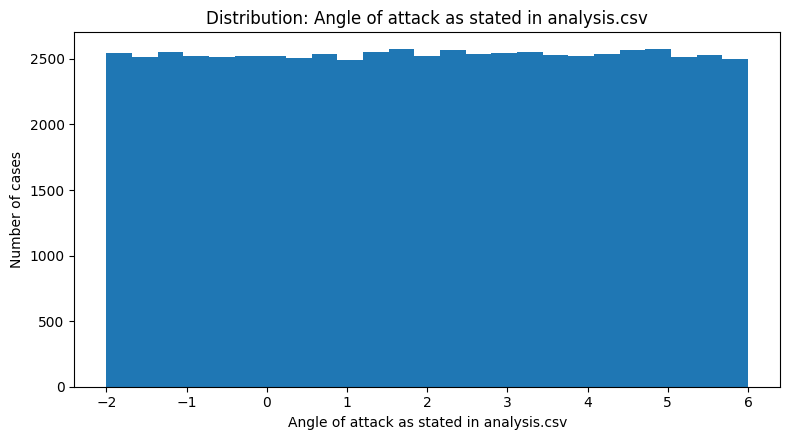

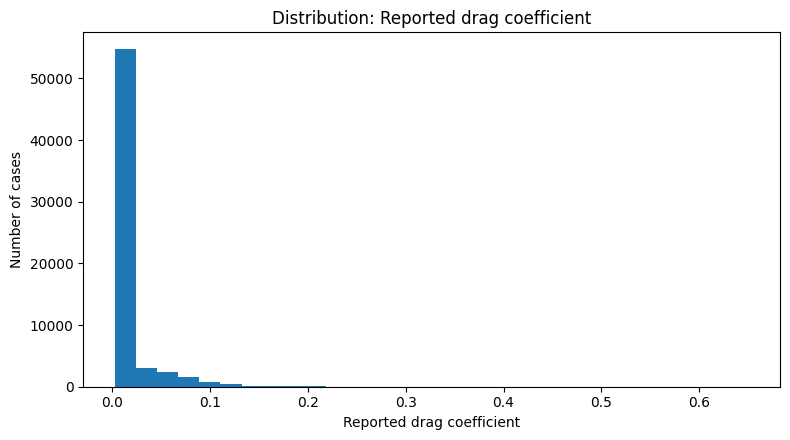

In [25]:
hist_specs = [
    ("Mach", "Mach number", 30, False),
    ("Re", "Reynolds number", 30, True),
    ("AoA_stated", "Angle of attack as stated in analysis.csv", 25, False),
    ("CD_reported", "Reported drag coefficient", 30, False),
]
for col, label, bins, logx in hist_specs:
    if col not in cases or cases[col].dropna().empty:
        print(f"Skipping {label}: column is absent or empty.")
        continue
    values = pd.to_numeric(cases[col], errors="coerce").dropna()
    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.hist(values, bins=bins)
    ax.set_title(f"Distribution: {label}")
    ax.set_xlabel(label)
    ax.set_ylabel("Number of cases")
    if logx and (values > 0).all():
        ax.set_xscale("log")
    fig.tight_layout()
    if SAVE_PLOTS:
        fig.savefig(PREP_DIR / "visualizations" / f"hist_{col}.png", dpi=160, bbox_inches="tight")
    plt.show()

## 14. Visualisation: residual reduction and drag-history stability

The vertical line at 6 orders marks the empirical residual screening threshold used by this notebook. The horizontal line at 0.001 (0.1%) is used only for the `keep_rq1_strict` sensitivity subset. These lines represent code settings, not universal CFD standards.

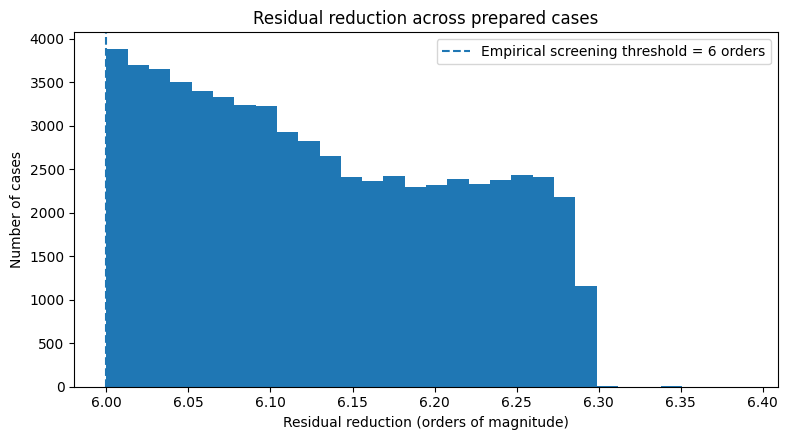

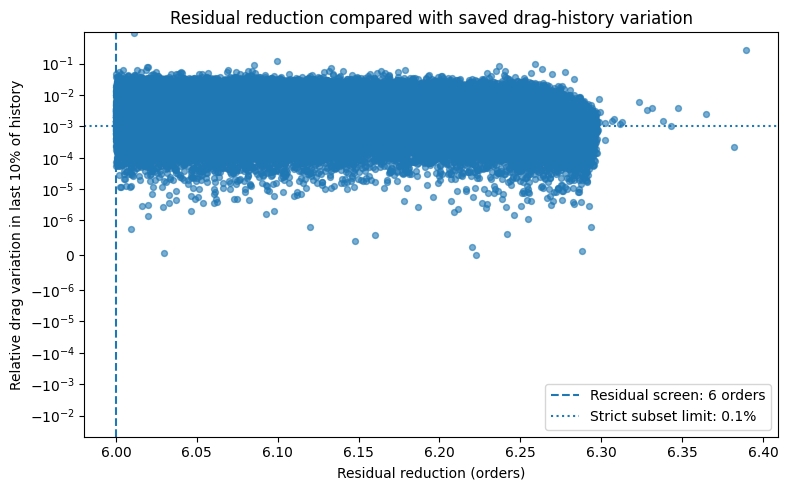

In [26]:
if "residual_drop_orders" in cases:
    d = pd.to_numeric(cases["residual_drop_orders"], errors="coerce").dropna()
    if len(d):
        fig, ax = plt.subplots(figsize=(8, 4.5))
        ax.hist(d, bins=30)
        ax.axvline(6.0, linestyle="--", label="Empirical screening threshold = 6 orders")
        ax.set_xlabel("Residual reduction (orders of magnitude)")
        ax.set_ylabel("Number of cases")
        ax.set_title("Residual reduction across prepared cases")
        ax.legend()
        fig.tight_layout()
        if SAVE_PLOTS:
            fig.savefig(PREP_DIR / "visualizations" / "residual_drop_distribution.png", dpi=160, bbox_inches="tight")
        plt.show()

if {"residual_drop_orders", "cd_tail_rel_change"}.issubset(cases.columns):
    tmp = cases[["residual_drop_orders", "cd_tail_rel_change"]].apply(pd.to_numeric, errors="coerce").dropna()
    if len(tmp):
        fig, ax = plt.subplots(figsize=(8, 5))
        ax.scatter(tmp["residual_drop_orders"], tmp["cd_tail_rel_change"], s=18, alpha=0.6)
        ax.axvline(6.0, linestyle="--", label="Residual screen: 6 orders")
        ax.axhline(0.001, linestyle=":", label="Strict subset limit: 0.1%")
        # Symmetric-log scale can display exact zeros as well as very small positive changes.
        ax.set_yscale("symlog", linthresh=1e-6)
        ax.set_xlabel("Residual reduction (orders)")
        ax.set_ylabel("Relative drag variation in last 10% of history")
        ax.set_title("Residual reduction compared with saved drag-history variation")
        ax.legend()
        fig.tight_layout()
        if SAVE_PLOTS:
            fig.savefig(PREP_DIR / "visualizations" / "residual_vs_cd_stability.png", dpi=160, bbox_inches="tight")
        plt.show()

## 15. Inspect one actual prepared case

The following cell selects the first case marked usable for RQ1 by default. You can replace `SELECT_AIRFOIL` and `SELECT_CASE` with the identifiers you want to inspect. It reads only the selected case's rows from the Parquet files when the installed Parquet engine supports filters.

In [27]:
# Change these to specific IDs, or leave both as None to auto-select a kept case.
SELECT_AIRFOIL = None
SELECT_CASE = None

if cases.empty:
    raise ValueError("cases.csv contains no cases to inspect. Check the preprocessing output/report.")

if SELECT_AIRFOIL is None or SELECT_CASE is None:
    if "keep_rq1" in cases and cases.keep_rq1.any():
        selected = cases.loc[cases.keep_rq1].iloc[0]
    else:
        selected = cases.iloc[0]
    SELECT_AIRFOIL = int(selected["airfoil"])
    SELECT_CASE = int(selected["case"])
else:
    matched = cases[(cases.airfoil == int(SELECT_AIRFOIL)) & (cases.case == int(SELECT_CASE))]
    if matched.empty:
        raise KeyError(f"Case airfoil={SELECT_AIRFOIL}, case={SELECT_CASE} is not in cases.csv")
    selected = matched.iloc[0]

print(f"Selected airfoil={SELECT_AIRFOIL}, case={SELECT_CASE}")
show_cols = [c for c in ["Mach", "Re", "AoA_stated", "CL_reported", "CD_reported", "t_max", "x_t_max",
                         "camber_max", "x_camber_max", "residual_drop_orders", "keep_rq1", "keep_rq2", "keep_rq1_strict"]
             if c in selected.index]
display(pd.DataFrame({"value": selected[show_cols]}))

SURFACE_DIR = PREP_DIR / "surfaces"
SURFACE_COLUMNS = ["airfoil", "case", "surface", "i", "x", "y", "cp", "cf", "cfx"]
def load_selected_surface(airfoil_id, case_id):
    chunks = []
    paths = sorted(SURFACE_DIR.glob("*.parquet"))
    for path in paths:
        try:
            part = pd.read_parquet(
                path, columns=SURFACE_COLUMNS,
                filters=[("airfoil", "==", int(airfoil_id)), ("case", "==", int(case_id))]
            )
        except (TypeError, ValueError, KeyError):
            part = pd.read_parquet(path, columns=SURFACE_COLUMNS)
            part = part[(part.airfoil == int(airfoil_id)) & (part.case == int(case_id))]
        if not part.empty:
            chunks.append(part)
    if not chunks:
        return pd.DataFrame(columns=SURFACE_COLUMNS)
    return pd.concat(chunks, ignore_index=True).sort_values(["surface", "i"])

surface_case = load_selected_surface(SELECT_AIRFOIL, SELECT_CASE)
if surface_case.empty:
    print("No surface rows found for this case. Check the case IDs and prepared/surfaces files.")
else:
    display(surface_case.groupby("surface").agg(points=("x", "size"), x_min=("x", "min"), x_max=("x", "max")))

Selected airfoil=1, case=0


,value
Mach,0.339795
Re,2890000.0
AoA_stated,2.724399
CL_reported,-0.000422
CD_reported,0.008874
t_max,0.293177
x_t_max,0.36
camber_max,0.016185
x_camber_max,0.545
residual_drop_orders,6.165095


,points,x_min,x_max
surface,,,
lower,158,-0.000002,0.999988
upper,148,-0.000002,0.999988


## 16. Visualisation: geometry, pressure coefficient and skin friction

The figures below are generated from the selected case's prepared surface data. The conventional pressure-coefficient plot has an inverted vertical axis so more negative pressure coefficients appear higher on the graph.

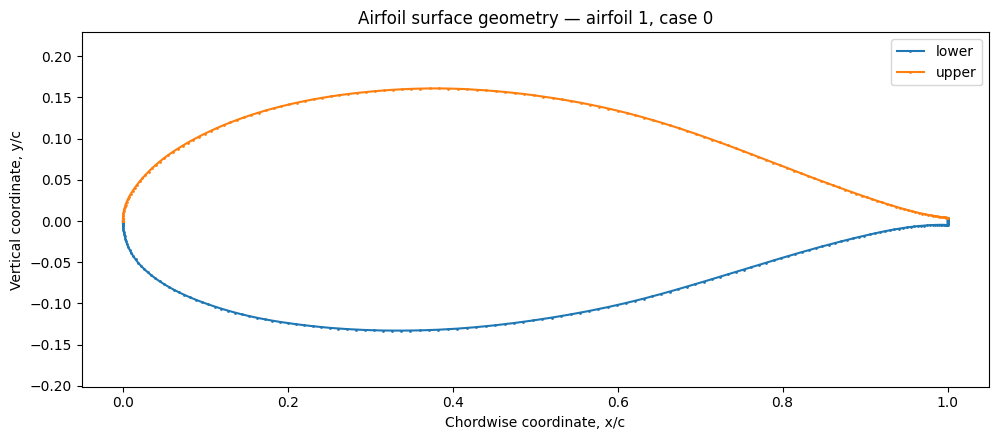

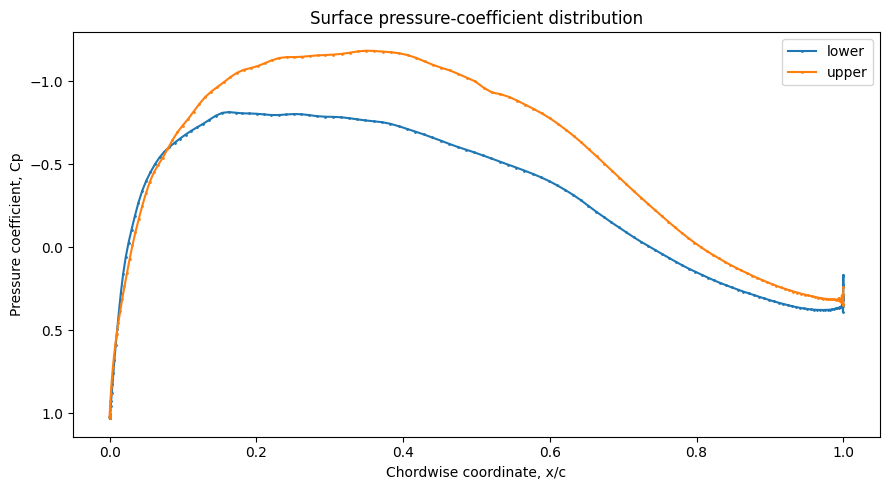

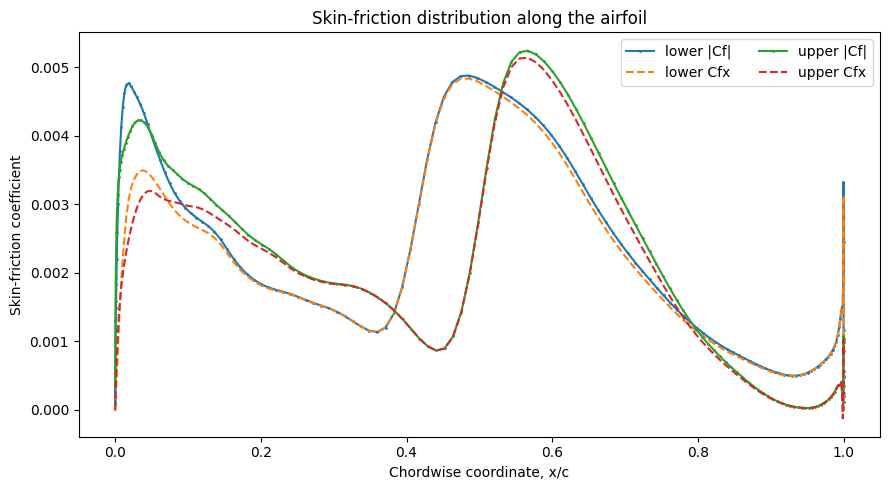

In [28]:
if not surface_case.empty:
    # Airfoil geometry
    fig, ax = plt.subplots(figsize=(10, 4.5))
    for side, g in surface_case.groupby("surface"):
        ax.plot(g["x"], g["y"], marker=".", markersize=2, label=side)
    ax.set_xlabel("Chordwise coordinate, x/c")
    ax.set_ylabel("Vertical coordinate, y/c")
    ax.set_title(f"Airfoil surface geometry — airfoil {SELECT_AIRFOIL}, case {SELECT_CASE}")
    ax.axis("equal")
    ax.legend()
    fig.tight_layout()
    if SAVE_PLOTS:
        fig.savefig(PREP_DIR / "visualizations" / f"case_{SELECT_AIRFOIL}_{SELECT_CASE}_geometry.png", dpi=160, bbox_inches="tight")
    plt.show()

    # Pressure coefficient
    fig, ax = plt.subplots(figsize=(9, 5))
    for side, g in surface_case.groupby("surface"):
        ax.plot(g["x"], g["cp"], marker=".", markersize=2, label=side)
    ax.invert_yaxis()
    ax.set_xlabel("Chordwise coordinate, x/c")
    ax.set_ylabel("Pressure coefficient, Cp")
    ax.set_title("Surface pressure-coefficient distribution")
    ax.legend()
    fig.tight_layout()
    if SAVE_PLOTS:
        fig.savefig(PREP_DIR / "visualizations" / f"case_{SELECT_AIRFOIL}_{SELECT_CASE}_cp.png", dpi=160, bbox_inches="tight")
    plt.show()

    # Skin friction magnitude and streamwise component
    fig, ax = plt.subplots(figsize=(9, 5))
    for side, g in surface_case.groupby("surface"):
        ax.plot(g["x"], g["cf"], marker=".", markersize=2, label=f"{side} |Cf|")
        ax.plot(g["x"], g["cfx"], linestyle="--", label=f"{side} Cfx")
    ax.set_xlabel("Chordwise coordinate, x/c")
    ax.set_ylabel("Skin-friction coefficient")
    ax.set_title("Skin-friction distribution along the airfoil")
    ax.legend(ncol=2)
    fig.tight_layout()
    if SAVE_PLOTS:
        fig.savefig(PREP_DIR / "visualizations" / f"case_{SELECT_AIRFOIL}_{SELECT_CASE}_cf.png", dpi=160, bbox_inches="tight")
    plt.show()
else:
    print("Plots skipped because the selected case has no prepared surface data.")

## 17. Visualisation: N-factor envelope (when available)

The embedded preprocessing code saves usable N-factor envelope data when it can build it from the individual wave-frequency zones. The solver's own envelope, kept for comparison (step 5), is drawn as a dashed line when it has been saved. Cases with no usable N-factor data can still have a valid solver-reported transition location; missing cross-check data should not be misrepresented as a threshold crossing.

The solver's own envelope is not saved yet (run Section 7 once with REDO_SOLVER_ENVELOPE = True).


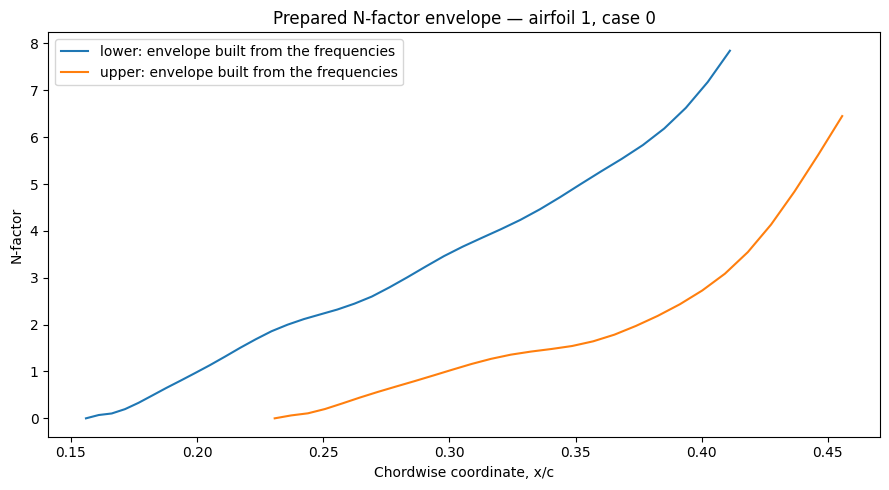

In [29]:
TRANSITION_DIR = PREP_DIR / "transition_inputs"
SOLVER_ENV_DIR = PREP_DIR / "solver_envelopes"
NFACTOR_COLUMNS = ["airfoil", "case", "surface", "x", "N"]
def load_selected_envelope(folder, airfoil_id, case_id):
    chunks = []
    for path in sorted(Path(folder).glob("*.parquet")):
        try:
            part = pd.read_parquet(path, columns=NFACTOR_COLUMNS,
                                   filters=[("airfoil", "==", int(airfoil_id)), ("case", "==", int(case_id))])
        except (TypeError, ValueError, KeyError):
            part = pd.read_parquet(path, columns=NFACTOR_COLUMNS)
            part = part[(part.airfoil == int(airfoil_id)) & (part.case == int(case_id))]
        if not part.empty:
            chunks.append(part)
    if not chunks:
        return pd.DataFrame(columns=NFACTOR_COLUMNS)
    return pd.concat(chunks, ignore_index=True).sort_values(["surface", "x"])

nf_case = load_selected_envelope(TRANSITION_DIR, SELECT_AIRFOIL, SELECT_CASE)
solver_case = load_selected_envelope(SOLVER_ENV_DIR, SELECT_AIRFOIL, SELECT_CASE)
if nf_case.empty and solver_case.empty:
    print("No usable N-factor envelope was saved for this selected case.")
else:
    fig, ax = plt.subplots(figsize=(9, 5))
    for side, g in nf_case.groupby("surface"):
        ax.plot(g["x"], g["N"], label=f"{side}: envelope built from the frequencies")
    for side, g in solver_case.groupby("surface"):
        ax.plot(g["x"], g["N"], linestyle="--", label=f"{side}: solver's own envelope")
    if solver_case.empty:
        print("The solver's own envelope is not saved yet (run Section 7 once with REDO_SOLVER_ENVELOPE = True).")
    ax.set_xlabel("Chordwise coordinate, x/c")
    ax.set_ylabel("N-factor")
    ax.set_title(f"Prepared N-factor envelope — airfoil {SELECT_AIRFOIL}, case {SELECT_CASE}")
    ax.legend()
    fig.tight_layout()
    if SAVE_PLOTS:
        fig.savefig(PREP_DIR / "visualizations" / f"case_{SELECT_AIRFOIL}_{SELECT_CASE}_nfactor.png", dpi=160, bbox_inches="tight")
    plt.show()

## 18. Inspect the preprocessing report and removal-by-band table

PREPROCESSING REPORT

cases: 63,373 on 4,618 airfoils
kept for RQ1 (drag, crossover):      63,372 (100.0%)
kept for RQ2 (also transition valid): 63,078 (99.5%)
RQ1 sensitivity subset (also steady CD history): 19,162 (30.2%)

settings (fixed before the run; methodology Tables 3.4 and 3.6):
  converged = total residual fell by at least 6 orders of magnitude.
  Own choice, fixed in advance, because UniFoil does not publish its stopping rule;
  a looser rule of 5 orders is compared below as a sensitivity check.
  sensitivity only: CD in the saved history changed by at most 0.1% over the last
  10 % of iterations (our choice; used only for keep_rq1_strict, never to remove cases)
  at least 50 slice points on each surface
  RQ1 needs: analysis, convergence, slices   RQ2 also needs: transiLoc.dat
  e^N cross-check only (reported, not removed): nfactor_ts.dat, bledge_info.dat

run environment:
  dataset revision: 6724bb9691e866655446543aa3ee16cf78f26b5f (fixed for the study: 6724bb9)
  Python 

,cases,removed_rq1,removed_rq2,kept_rq1_strict
"Mach (0.099, 0.3]",17176,0.0,0.004774,0.045238
"Mach (0.3, 0.5]",17184,0.0,0.005587,0.398219
"Mach (0.5, 0.7]",17085,0.0,0.003395,0.457536
"Mach (0.7, 0.86]",11927,0.0,0.004863,0.312317
"Re (999999.999, 3250000.0]",15911,0.0,0.007291,0.218402
"Re (3250000.0, 5500000.0]",15908,0.0,0.005029,0.382072
"Re (5500000.0, 7750000.0]",15918,0.0,0.003581,0.329815
"Re (7750000.0, 10100000.0]",15635,0.0,0.002622,0.278798
"AoA_stated (-2.0109999999999997, 0.0]",15809,0.0,0.004871,0.311721
"AoA_stated (0.0, 2.0]",15822,0.0,0.004045,0.303312


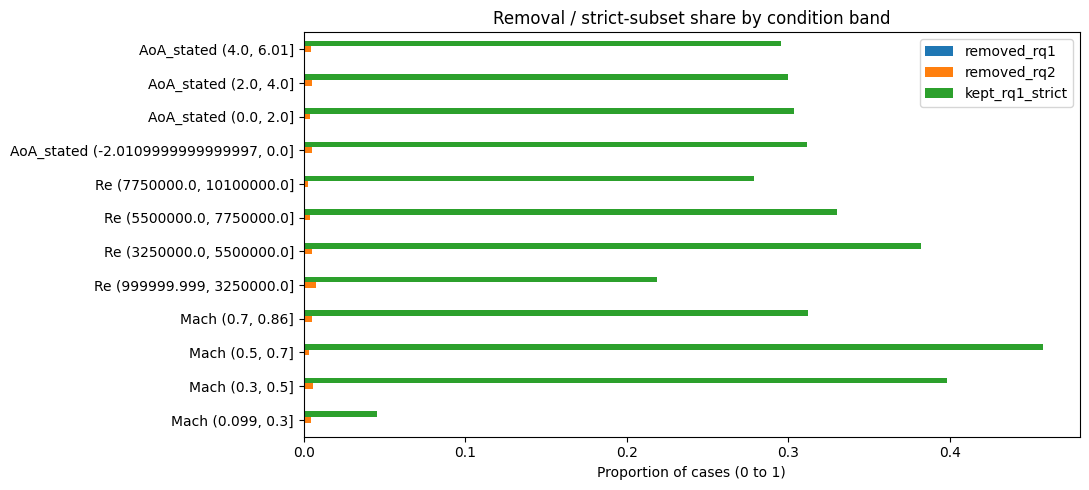

In [30]:
REPORT_PATH = PREP_DIR / "preprocessing_report.txt"
if REPORT_PATH.is_file():
    print(REPORT_PATH.read_text(errors="replace"))
else:
    print("No preprocessing_report.txt found.")

BAND_PATH = PREP_DIR / "removal_by_band.csv"
if BAND_PATH.is_file():
    bands = pd.read_csv(BAND_PATH, index_col=0)
    display(bands)
    cols = [c for c in ["removed_rq1", "removed_rq2", "kept_rq1_strict"] if c in bands]
    if cols:
        fig, ax = plt.subplots(figsize=(11, max(5, 0.32 * len(bands))))
        bands[cols].plot(kind="barh", ax=ax)
        ax.set_xlabel("Proportion of cases (0 to 1)")
        ax.set_title("Removal / strict-subset share by condition band")
        ax.legend(loc="best")
        fig.tight_layout()
        if SAVE_PLOTS:
            fig.savefig(PREP_DIR / "visualizations" / "removal_by_band.png", dpi=160, bbox_inches="tight")
        plt.show()
else:
    print("No removal_by_band.csv found. It is generated when usable flight-condition bands are available.")

## 19. Export and final checklist

If `SAVE_PLOTS=True`, figures are saved under `PREP_DIR/visualizations/`. The notebook does not export or modify raw files.

In [31]:
print("Prepared folder:", PREP_DIR.resolve())
print("Cases table:", CASES_PATH, "exists =", CASES_PATH.is_file())
print("Surface Parquet files:", len(list((PREP_DIR / "surfaces").glob("*.parquet"))))
print("N-factor Parquet files:", len(list((PREP_DIR / "transition_inputs").glob("*.parquet"))))
print("Solver-envelope Parquet files:", len(list((PREP_DIR / "solver_envelopes").glob("*.parquet")))
      if (PREP_DIR / "solver_envelopes").exists() else 0)
print("Saved visualisations:", len(list((PREP_DIR / "visualizations").glob("*.png"))) if (PREP_DIR / "visualizations").exists() else 0)

print("\nAgainst methodology Section 3.5:")
for name, what in [("checks_passed.txt", "assertions passed (Section 4.6)"),
                   ("run_environment.txt", "dataset revision and package versions recorded"),
                   ("flag_inspection_sample.csv", "random sample of flagged and unflagged cases saved for inspection (Section 9)"),
                   ("aoa_check_test1.csv", "angle-of-attack check, test 1 (Section 10.1)"),
                   ("aoa_check_test2.csv", "angle-of-attack check, test 2 (Section 10.2)"),
                   ("removal_by_band.csv", "bias check by Mach, Reynolds-number and AoA band"),
                   ("preprocessing_report.txt", "plain-text report of settings, removals and results")]:
    print(f"  [{'x' if (PREP_DIR / name).is_file() else ' '}] {what}  ({name})")

Prepared folder: /content/drive/MyDrive/unifoil_project/prepared
Cases table: /content/drive/MyDrive/unifoil_project/prepared/cases.csv exists = True
Surface Parquet files: 32
N-factor Parquet files: 32
Solver-envelope Parquet files: 0
Saved visualisations: 18

Against methodology Section 3.5:
  [x] assertions passed (Section 4.6)  (checks_passed.txt)
  [x] dataset revision and package versions recorded  (run_environment.txt)
  [x] random sample of flagged and unflagged cases saved for inspection (Section 9)  (flag_inspection_sample.csv)
  [x] angle-of-attack check, test 1 (Section 10.1)  (aoa_check_test1.csv)
  [x] angle-of-attack check, test 2 (Section 10.2)  (aoa_check_test2.csv)
  [x] bias check by Mach, Reynolds-number and AoA band  (removal_by_band.csv)
  [x] plain-text report of settings, removals and results  (preprocessing_report.txt)


## Quick interpretation guide

- **Residual-drop histogram:** shows how the cases compare with the convergence rule of the chapter (at least 6 orders; 5 orders as a check).
- **`keep_rq1` / `keep_rq2`:** different eligibility criteria for drag/crossover and transition-related analyses (Table 3.4).
- **Hand-inspection sample (Section 9):** each sampled case with the values its flags are based on, and the raw-file evidence.
- **Angle-of-attack check (Section 10):** the stated AoA is used as stated only if both tests confirm it.
- **Geometry / Cp / Cf plots:** let you visually inspect the reconstructed surface coordinates and coefficients for one case.
- **N-factor plot:** the envelope built from the frequencies, and the solver's own envelope (dashed) when saved.
- **Removal-by-band plot:** the bias check of step 7: similar removal shares in every band show that the screening does not change the balance of the sample.

This notebook only prepares and checks the data. It reports no findings: the drag split (with its closure check), the crossover identification, the transition location extractor and the RQ2 link test are later steps of the methodology, each with its own notebook.